[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anita-agasaveeran/Assignment4/blob/main/01_CRISP-DM_Wine_Value/notebooks/CRISP_DM_Wine_Value.ipynb)

# The $20 Bottle That Drinks Like $60: Finding Value Wines with CRISP-DM
**CMPE 255 · Assignment 4 · Project 1 of 3**

This notebook follows all six phases of CRISP-DM 1.0 (Chapman et al., 2000) and every generic task in each phase, on about 120,000 real WineEnthusiast reviews. Each task ends with the outputs the CRISP-DM user guide lists for it.

| Phase | Tasks |
|---|---|
| 1. Business Understanding | Determine business objectives · Assess situation · Determine data mining goals · Produce project plan |
| 2. Data Understanding | Collect initial data · Describe data · Explore data · Verify data quality |
| 3. Data Preparation | Select · Clean · Construct · Integrate · Format data |
| 4. Modeling | Select modeling technique · Generate test design · Build model · Assess model |
| 5. Evaluation | Evaluate results · Review process · Determine next steps |
| 6. Deployment | Plan deployment · Plan monitoring & maintenance · Produce final report · Review project |

Supporting code lives in `src/winevalue/`. The written report is `reports/final_report.md`, and critic reviews for each phase are in `critiques/`.

*Data: [Wine Reviews](https://www.kaggle.com/datasets/zynicide/wine-reviews) by Zack Thoutt, scraped from WineEnthusiast in June 2017, CC BY-NC-SA 4.0. This notebook and its outputs are shared under the same licence.*

## 0. Setup

In [1]:
# Works in Google Colab and locally. In Colab: clone the repo and install requirements.
import os, subprocess, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/anita-agasaveeran/Assignment4.git"

if IN_COLAB:
    if not Path("/content/Assignment4").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/Assignment4"], check=True)
    PROJECT_DIR = Path("/content/Assignment4/01_CRISP-DM_Wine_Value")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    "/content/Assignment4/requirements.txt"], check=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(PROJECT_DIR / "src"))
os.chdir(PROJECT_DIR)
print("Project dir:", PROJECT_DIR)

Project dir: /Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from winevalue import config
from winevalue.data import load_raw, extract_vintage
from winevalue.grapes import grape_canonical, wine_colour

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(config.SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")

python 3.12.14 | pandas 3.1.0 | sklearn 1.9.1


---
# Phase 1 · Business Understanding

> **Revision 3** (+ round-3 polish), after critic rounds 1 (7/10), 2 (8/10) and 3 (9/10, no major issues); see `critiques/phase1_business_understanding_round*.md`.
> - **Round 2 changes:** targets re-set so **every** development fold passes them, with uncertainty conditions; a pilot gate measured *relative* to note-blind rules; simple rules and RNG streams frozen in `src/`; a broader masking list; pre-registered insight hypotheses.
> - **Round 1 changes:** simulated buying cycles; a fixed simple-rule set; the region confound measured; development-only score statistics.

### 1.1 Determine business objectives

**CRISP-DM outputs:** Background · Business objectives · Business success criteria

#### Background
Critic scores sell wine. A "90 points" tag is one of the strongest quality signals a shopper has. But most wines a retailer considers have **no critic score yet**: new vintages, small producers, new imports. What the retailer usually has is a **tasting note** from the importer, the producer or its own staff, plus basic facts (origin, grape, vintage, price).

This project imagines a **hypothetical stakeholder**: the buying team of an online wine retailer. No company was interviewed, so parameters are explicit assumptions (§1.2). The team wants a *"Great Value: 90+ points for $25 or less"* collection. Each buying cycle it receives about **1,000 unscored ≤ $25 candidates** (A7) and can sample about **100** (A4).

The data is 129,971 WineEnthusiast reviews scraped in June 2017. Counts come first. Score statistics come only after the evaluation design is fixed, so they can exclude the lockbox.

In [3]:
# What is in the data? Counts only (no scores yet: the lockbox is defined in the next cell)
raw = load_raw()
df = raw.drop_duplicates().copy()          # provisional for sizing; Phase 3 formalises de-duplication
df["vintage"] = extract_vintage(df["title"])
repeat_titles = df["title"].value_counts()
overview = pd.Series({
    "raw rows": len(raw),
    "exact duplicate rows": raw.duplicated().sum(),
    "unique reviews": len(df),
    "repeat reviews of an already-reviewed title": int((repeat_titles - 1).clip(lower=0).sum()),
    "titles reviewed more than once": int((repeat_titles > 1).sum()),
    "countries": df["country"].nunique(),
    "grape varieties": df["variety"].nunique(),
    "wineries": df["winery"].nunique(),
    "named critics": df["taster_name"].nunique(),
    "reviews with no critic name": df["taster_name"].isna().sum(),
    "reviews with no price": df["price"].isna().sum(),
})
display(overview.to_frame("count"))

,count
raw rows,129971
exact duplicate rows,9983
unique reviews,119988
repeat reviews of an already-reviewed title,1148
titles reviewed more than once,934
countries,43
grape varieties,707
wineries,16757
named critics,19
reviews with no critic name,24917


#### Evaluation design (fixed now so no later phase can tune on the test data)
**What a buyer would face:** notes from writers the model has never seen. So whole critics are held out:
- **Critic folds.** The 19 named critics are dealt into 5 folds with balanced review counts.
- **Lockbox.** One fold with ≥ 3 critics is sealed as the **lockbox**, chosen with the project seed. Its *scores* aren't examined until Phase 5.
- **Development.** The other 4 folds are used for cross-validation.
- **Anonymous reviews** are used for training only.

Critics specialise by region, so holding out a critic also removes much of the training data for their regions. The coverage columns measure this using categorical columns only, which is allowed for the lockbox.

In [4]:
# Evaluation design, fixed now: critic-grouped folds, with one lockbox fold sealed until Phase 5
from winevalue.splits import critic_folds, assign_folds

mapping, LOCKBOX = critic_folds(df["taster_name"])
df["fold"] = assign_folds(df)
role = lambda f: "training only (anonymous)" if f == -1 else ("LOCKBOX (Phase 5 only)" if f == LOCKBOX else "cross-validation")

# Coverage: how much of each fold's wine "territory" the rest of the data still covers.
# Uses only categorical columns (no scores), so it's allowed for the lockbox too.
rows = []
for f in sorted(df["fold"].unique()):
    te = df[df["fold"] == f]
    tr = df[(df["fold"] != f) & (df["fold"] != LOCKBOX)] if f != LOCKBOX else df[df["fold"] != LOCKBOX]
    vc_counts = tr.groupby(["variety", "country"]).size()
    vc_key = pd.MultiIndex.from_frame(te[["variety", "country"]])
    rows.append({
        "fold": f, "role": role(f), "reviews": len(te),
        "critics": ", ".join(sorted(te["taster_name"].fillna("(anonymous)").unique())),
        "top countries": ", ".join(f"{c} {s:.0%}" for c, s in te["country"].value_counts(normalize=True).head(3).items()),
        "variety×country seen ≥20× in training": vc_counts.reindex(vc_key).fillna(0).ge(20).mean() if f != -1 else np.nan,
        "winery seen in training": te["winery"].isin(set(tr["winery"])).mean() if f != -1 else np.nan,
    })
fold_table = pd.DataFrame(rows).set_index("fold")
display(fold_table)

# From here on, Phases 1-4 never look at lockbox scores.
dev = df[df["fold"] != LOCKBOX].copy()
print(f"Development data: {len(dev):,} reviews; lockbox sealed: {(df['fold'] == LOCKBOX).sum():,} reviews")

,role,reviews,critics,top countries,variety×country seen ≥20× in training,winery seen in training
fold,,,,,,
-1,training only (anonymous),24917,(anonymous),"US 64%, Italy 32%, Australia 1%",NaN,NaN
0,cross-validation,23560,Roger Voss,"France 73%, Portugal 22%, Austria 5%",0.570586,0.105645
1,cross-validation,17812,"Jim Gordon, Michael Schachner","Spain 34%, Chile 23%, US 22%",0.292331,0.303447
2,LOCKBOX (Phase 5 only),17884,"Anne Krebiehl MW, Jeff Jenssen, Kerin O’Keefe, Sean P. Sullivan","Italy 54%, US 25%, Austria 11%",0.900973,0.730597
3,cross-validation,17810,"Anna Lee C. Iijima, Carrie Dykes, Christina Pickard, Fiona Adams, Joe Czerwinski, Paul...","US 63%, Germany 11%, Australia 11%",0.872656,0.318585
4,cross-validation,18005,"Alexander Peartree, Lauren Buzzeo, Matt Kettmann, Mike DeSimone, Susan Kostrzewa, Virg...","US 84%, South Africa 7%, France 3%",0.850708,0.705304


Development data: 102,104 reviews; lockbox sealed: 17,884 reviews


In [5]:
# Lockbox composition for per-critic reporting (counts only; no scores)
lb = df[df["fold"] == LOCKBOX]
lb_pool = lb[lb["price"] <= config.VALUE_MAX_PRICE]
display(lb_pool["taster_name"].value_counts().rename("≤$25 candidates").to_frame()
        .assign(share=lambda t: t["≤$25 candidates"] / t["≤$25 candidates"].sum()).round(3))

,≤$25 candidates,share
taster_name,,
Kerin O’Keefe,3697,0.504
Sean P. Sullivan,1757,0.240
Anne Krebiehl MW,1544,0.211
Jeff Jenssen,336,0.046


**What the lockbox tests:** new writers, in a mix of regions.
- Italy is 54% of the lockbox, but anonymous training notes still cover Italy.
- Lockbox coverage (90% variety × country, 73% winery) is better than in development folds 0 and 1, so it isn't the hardest fold. The closest development fold is **fold 3** (87% coverage, several critics, US-heavy), and every target below is checked against fold 3.
- **One critic dominates the lockbox's ≤ $25 pool:** Kerin O'Keefe has 50% of it, and Jeff Jenssen only 336 wines. Per-critic results are therefore reported as precision in the top 10% of each critic's pool, and Jenssen's are marked low-confidence.

,reviews,median_price,p90_price
points,,,
80-84,11674,15.0,32.0
85-87,31369,18.0,39.0
88-90,32464,26.0,55.0
91-93,21611,44.0,85.0
94-100,4986,74.0,200.0


Score: mean 88.3, SD 3.2. Corr(points, log price) = 0.63
Wines at or under $25: 51.8% of priced reviews; of those, 15.0% score 90+ ('value wines')


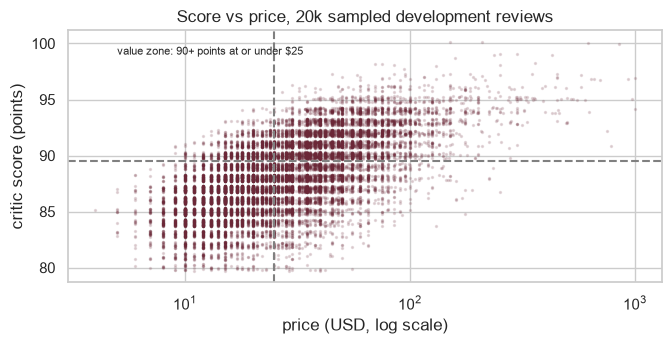

In [6]:
# Price vs score and how rare value wines are (development data only)
bands = pd.cut(dev["points"], [79, 84, 87, 90, 93, 100], labels=["80-84", "85-87", "88-90", "91-93", "94-100"])
display(dev.groupby(bands, observed=True).agg(reviews=("points", "size"), median_price=("price", "median"),
                                             p90_price=("price", lambda s: s.quantile(0.9))))
priced = dev[dev["price"].notna()]
under_cap = priced["price"] <= config.VALUE_MAX_PRICE
is_value = under_cap & (priced["points"] >= config.VALUE_MIN_POINTS)
print(f"Score: mean {dev['points'].mean():.1f}, SD {dev['points'].std():.1f}. "
      f"Corr(points, log price) = {np.corrcoef(priced['points'], np.log(priced['price']))[0, 1]:.2f}")
print(f"Wines at or under ${config.VALUE_MAX_PRICE:.0f}: {under_cap.mean():.1%} of priced reviews; "
      f"of those, {is_value[under_cap].mean():.1%} score {config.VALUE_MIN_POINTS}+ ('value wines')")

fig, ax = plt.subplots(figsize=(7, 3.6))
sample = priced.sample(20_000, random_state=config.SEED)
ax.scatter(sample["price"], sample["points"] + np.random.default_rng(0).uniform(-0.3, 0.3, len(sample)), s=2, alpha=0.15, color="#6b2737")
ax.set_xscale("log"); ax.axvline(config.VALUE_MAX_PRICE, ls="--", c="grey"); ax.axhline(config.VALUE_MIN_POINTS - 0.5, ls="--", c="grey")
ax.text(5, 99, "value zone: 90+ points at or under $25", fontsize=8)
ax.set(xlabel="price (USD, log scale)", ylabel="critic score (points)", title="Score vs price, 20k sampled development reviews")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "p1_score_vs_price.png", dpi=150); plt.show()

**What this shows (development data):**
- Price predicts quality only partly (correlation 0.63 with log price). Median prices go from $26 at 88–90 points to $74 at 94+, with a long tail of cheap wines in every band.
- About half of priced wines cost ≤ $25, and 15% of those score 90+. In the critic-fold candidate pools used for the simulations the rate is **17.6%**. (The 15% figure also includes anonymous reviews.)
- So a team sampling 100 of 1,000 candidates at random would find about **18 value wines**.

#### Business objectives
- **BO1, value shortlist:** rank each cycle's ~1,000 unscored ≤ $25 candidates so the ~100 samples contain as many 90+ wines as possible.
- **BO2, internal score estimate:** an *estimated score band* (e.g. "est. 88–91") for buyers' planning until a real review arrives. **Internal only:** never shown to customers as WineEnthusiast points (R10).
- **BO3, shelf navigation:** flavour profiles and descriptor–grape links for collection pages.
- **BO4, catalogue quality:** detect duplicate and near-duplicate listings; "similar wines".
- **BO5, critic calibration and buyer insights:** quantify how much a score depends on who tasted the wine, and which wine attributes go with value.

Out of scope: price setting, demand forecasting, personalised recommendations (no customer data).

#### Business success criteria (pre-registered; thresholds in `config.py`)
- Measured **once**, in Phase 5, on the lockbox critics. Simple rules are scored on the same data.
- **Pass rule:** the point estimate meets the target **and** the stated lower bound holds.
- **Lower bounds** are one-sided 90%, from 500 bootstrap resamples of **wineries** (wines from the same producer move together).
- Every target below is met by **every** development fold of the untuned feasibility models (see the per-fold table in 1.2).

| ID | Criterion | Target | Lower-bound condition | Weakest development fold |
|---|---|---|---|---|
| BSC1 | **Shortlist.** Expected precision@100 of the DM2 ranker over 200 simulated cycles of 1,000 ≤ $25 candidates | ≥ 0.55 **and** ≥ 1.4× the best rule in the frozen **simple-rule set** (`winevalue.rules`: price, winery track record, province track record, variety × country, winery then price; random ties), as measured on the lockbox | Top-10% lift vs that rule ≥ 1.2× | P@100 0.61; lift 1.56×; lift lower bound 1.43× |
| BSC2 | **Internal score band.** Share of ≤ $25 candidates whose price-free estimate is within ±2 points | ≥ 0.60 and ≥ +5 pp over variety × country | Gain lower bound > 0 | 0.63; +7.3 pp (lower bound +6.0) |
| BSC3 | **Navigation.** Flavour profiles | 6–15 profiles, each ≥ 1% of wines. Two independent reviewer agents (**not** the analyst), each blind to the other, can each name ≥ 80% of profiles from their top terms with confidence ≥ 3/5 | Top-10-term Jaccard ≥ 0.5 between profiles fitted on two halves of the development data | – (Phase 4) |
| BSC4 | **Usability.** One screen. Inputs: note, country, grape, vintage, price. Outputs: est. score band, P(90+), value verdict, flavour profile, 5 similar wines | All shown in the recorded demo, < 3 s per query | – | – |
| BSC5 | **Buyer insights.** Pre-registered hypotheses H1–H6 (`config.HYPOTHESES`) | **≥ 4 of 6** replicate, **including H5 or H6**: stated direction and condition met in **both** development and lockbox data | As stated per hypothesis | – (Phase 4/5) |

**Pre-registered hypotheses (BSC5):**
- *Sanity checks (strong in development data):*
  - **H1:** longer notes go with higher scores (LB > 0).
  - **H2:** within a variety × country group, pricier wines score higher (LB > 0).
  - **H3:** a named designation goes with higher scores (same variety × country; LB > 0).
- **H4:** critics differ. The SD of critic effects (vs a training-fitted variety × country expectation) exceeds 0.5 points, **LB > 0.5**. *Limitation:* the lockbox has only 4 critics.
- *Actionable:*
  - **H5:** among ≤ $25 wines, whites are more often value wines than reds (LB > 0). The colour map is frozen in Phase 3, before any lockbox use.
  - **H6:** among ≤ $25 wines, a strong winery track record (shrunk mean ≥ 89, shrink = 20) goes with a higher value-wine rate (LB > 0).

**Necessary, not sufficient.** These criteria use *critic* notes, but the real use is on importer, producer or staff notes (A1). Deployment therefore also needs a **pilot gate** on **≥ 400 ≤ $25 retailer notes** for wines that later receive a critic score. On those same pilot wines, it must beat the note-blind rules:
- ±2 accuracy ≥ +5 pp over variety × country, with a lower bound > 0;
- the ranker's top-20% precision for 90+ wines ≥ 1.3× the **best frozen simple rule**, with a lower bound > 1.0.

400 wines give about 80% power at fold-3-like effects; 100 would pass a good model only 39–67% of the time. (`config.PILOT_*`)

### 1.2 Assess situation

**CRISP-DM outputs:** Inventory of resources · Requirements, assumptions & constraints · Risks & contingencies · Terminology · Costs & benefits

#### Inventory of resources
| Type | Resource |
|---|---|
| Data | Wine Reviews (Kaggle, Zack Thoutt): 129,971 WineEnthusiast reviews, scraped June 2017, CC BY-NC-SA 4.0. One table; no sales, inventory or customer data |
| People | One analyst (the author). **The stakeholder is hypothetical**, so business parameters (A1–A7) are explicit assumptions with sensitivity checks. No sommelier or domain expert available. Reviewers: course instructor + an independent critic; independent reviewer agents for BSC3 |
| Compute / software | Laptop + Google Colab; Python 3.12, pandas, scikit-learn, LightGBM, mlxtend, datasketch, statsmodels, Streamlit (all open source) |

#### Requirements
- **R-1, prediction timing:** when a buyer considers a wine, **before any critic review exists**. Available then: note, country/province/region, grape, winery and its *past* scores, vintage, price.
- **R-2, inputs by use:**
  - The **score estimate** (BO2) and **value verdict** exclude `price`, so "quality vs price" isn't circular.
  - The **shortlist ranker** (BO1/DM2) may use price: it's known at decision time and is itself a benchmark rule.
  - Neither may use `taster_name` / `taster_twitter_handle`.
- **R-3, honest test:**
  - The lockbox is scored once.
  - Exact duplicates are removed.
  - Test reviews whose wine title also appears in training are dropped (124 of the 934 repeat titles span folds).
  - Anonymous notes that a style classifier attributes to a lockbox critic with p > 0.5 are dropped from training (859 rows; see the check below).
- **R-4, reproducibility:**
  - Fixed seeds.
  - Cycles and tie-breaks use separate RNG streams, so every rule is scored on identical cycles.
  - The simple-rule set and the masking list are frozen in `src/`.
  - The notebook runs top to bottom in Colab and is saved with outputs.
- **R-5, licence:** derived outputs are shared under CC BY-NC-SA 4.0 with attribution.

#### Assumptions
| # | Assumption | Testable? | Handling |
|---|---|---|---|
| A1 | Retailer notes carry similar descriptive signal to critic notes | **Not with this data.** Leave-critic-out tests new *critics*, not new *kinds* of writer (producers have an incentive to praise) | Masking proxy (DM1b) now; **relative pilot gate** before deployment |
| A2 | 90+ points is a meaningful value bar | No | Also reported at 88+ / 92+ |
| A3 | 2017 prices still rank wines sensibly relative to each other | No | Ranking use only; cap also tested at $20 / $30 |
| A4 | ~100 samples per cycle | No | Also k = 50 / 200 |
| A5 | ~$25 per sample (bottle + buyer time); ~2 analyst-hours per cycle to re-score | No | Illustrative economics |
| A6 | Scores are honest; whether tastings were blind is unknown | No | Critic calibration descriptive |
| A7 | **~1,000 unscored ≤ $25 candidates per cycle** (importer and distributor catalogues for a mid-size online retailer) | No | Sensitivity at 500 / 2,000 |

#### Constraints
One static 2017 snapshot, no review dates. Only 80+ wines are published. No stakeholder interviews. One analyst and an academic timeline (§1.4).

**Anonymous-review check (R-3, R8).** Could some anonymous training notes be written by lockbox critics? A style classifier uses note *text* and critic names only, no scores. The threshold is chosen from its held-out accuracy:

In [7]:
# Could some anonymous training reviews be written by lockbox critics? A writing-style check.
# Uses note TEXT and critic names only (no scores), so the lockbox seal on scores is kept.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split
named_all = df[df["taster_name"].notna()]
tr_txt, te_txt = train_test_split(named_all, test_size=0.2, random_state=config.SEED, stratify=named_all["taster_name"])
vec = TfidfVectorizer(min_df=3, ngram_range=(1, 2), max_features=100_000, sublinear_tf=True).fit(tr_txt["description"])
clf = SGDClassifier(loss="log_loss", alpha=2e-6, max_iter=30, random_state=config.SEED).fit(vec.transform(tr_txt["description"]), tr_txt["taster_name"])
held = clf.predict_proba(vec.transform(te_txt["description"]))
held_ok = clf.classes_[held.argmax(1)] == te_txt["taster_name"].to_numpy()
anon = df[df["taster_name"].isna()]
proba = clf.predict_proba(vec.transform(anon["description"]))
top_p, top_critic = proba.max(axis=1), clf.classes_[proba.argmax(axis=1)]
lockbox_critics = [c for c, f in mapping.items() if f == LOCKBOX]
sens = pd.DataFrame([{"threshold": t,
                      "accuracy on held-out named notes above threshold": held_ok[held.max(1) > t].mean(),
                      "anonymous notes above threshold": int((top_p > t).sum()),
                      "of which attributed to a lockbox critic": int(((top_p > t) & np.isin(top_critic, lockbox_critics)).sum())}
                     for t in (0.5, 0.7, 0.9)]).set_index("threshold")
display(sens.round(3))
ANON_LOCKBOX_LIKE = anon.index[(top_p > config.ATTRIBUTION_THRESHOLD) & np.isin(top_critic, lockbox_critics)]
print(f"Overall held-out accuracy {held_ok.mean():.1%}. Rows dropped from training in Phase 3 (p > {config.ATTRIBUTION_THRESHOLD}): "
      f"{len(ANON_LOCKBOX_LIKE):,} ({len(ANON_LOCKBOX_LIKE) / len(anon):.1%} of anonymous notes)")

,accuracy on held-out named notes above threshold,anonymous notes above threshold,of which attributed to a lockbox critic
threshold,,,
0.5,0.992,11872,859
0.7,0.998,4418,329
0.9,1.000,341,29


Overall held-out accuracy 98.4%. Rows dropped from training in Phase 3 (p > 0.5): 859 (3.4% of anonymous notes)


At p > 0.5 the classifier is still **99.2%** accurate on held-out named notes. Dropping the 859 anonymous notes it assigns to lockbox critics costs only 3.4% of anonymous training data, so 0.5 is used (`config.ATTRIBUTION_THRESHOLD`).

#### Risks & contingencies
| # | Risk | Likelihood | Impact | Contingency |
|---|---|---|---|---|
| R1 | **Note-source shift** (A1) | High | High | Masking test (DM1b); relative pilot gate; BSCs "necessary, not sufficient" |
| R2 | **Region confound:** holding out critics also holds out regions (variety × country coverage 29–87% by development fold), so the variety × country baseline looks weaker than on a random split | Confirmed | Medium | Both splits reported; targets set on the critic split; per-fold and per-critic results |
| R3 | **Duplicates / repeat titles:** 9,983 dups; 1,148 repeat reviews of 934 titles; 124 titles span folds | Confirmed | High if ignored | Dups removed; test rows with a training title dropped |
| R4 | **Selection bias:** only 80+ wines are published | Confirmed | Medium | Stated limitation |
| R5 | **Stale prices**, single snapshot | Confirmed | Low–Medium | Ranking use only; cap sensitivity |
| R6 | **Critic differences** for the same variety and country | Observed (descriptive) | Medium | H4 / DM6; the lockbox mixes 4 critics |
| R7 | **Long-tail categories:** 707 grapes, 16,757 wineries | Confirmed | Medium | Rare-category grouping (Phase 3) |
| R8 | **Anonymous notes by lockbox critics** | Small | Low | 859 rows (p > 0.5) dropped from training |
| R9 | **Weak lockbox result.** Development margins are smallest for fold 3 (the fold most like the lockbox) on DM1/BSC2, and for folds 1 and 4 on BSC1 | Medium | Medium | Every target is met by every development fold; winery-clustered lower bounds; per-critic reporting |
| R10 | **Misleading or infringing display** of estimated "points" | Medium | Medium | Internal "estimated band" only, labelled |
| R11 | **One critic dominates the lockbox** (O'Keefe: 50% of the ≤ $25 pool) | Confirmed | Medium | Per-critic top-10% precision; results reported with and without O'Keefe |
| R12 | **Licence (NC-SA)** limits commercial use | Confirmed | Low (academic) | Stated in README and app |

#### Terminology
**Critic score / points:** WineEnthusiast's 80–100 rating · **Value wine:** 90+ points at ≤ $25 · **Tasting note:** the `description` · **Candidate pool / cycle:** unscored ≤ $25 wines considered in one buying round (A7) · **Shortlist:** the top k to sample · **Precision@k / top-10% precision:** share of a shortlist that are value wines · **Simple-rule set:** the frozen non-ML rankings in `winevalue.rules` · **Lift:** ranker precision ÷ best simple-rule precision · **MAE:** mean absolute error · **Within ±2:** share of estimates within 2 points · **Critic fold / lockbox:** a held-out group of critics / the fold sealed until Phase 5 · **Lower bound (LB):** one-sided 90% winery-clustered bootstrap bound · **Evaluative language:** words and phrases that state a verdict or drinking window (`config.EVALUATIVE_TERMS`, `EVALUATIVE_PATTERNS`) · **TF-IDF:** word weighting for notes · **Flavour profile:** a cluster of similar notes · **Support / confidence / lift (rules):** association-rule statistics · **MinHash LSH:** fast near-duplicate search.

#### Costs & benefits
**Feasibility check.** Development folds only; untuned models; test rows with a training title dropped. Shortlists are scored over 200 simulated cycles (cycles and ties on separate RNG streams, one tie stream per rule); lower bounds use a winery-clustered bootstrap. Training here uses all anonymous rows: the R-3 attribution filter (859 rows, none of them lockbox rows) starts in Phase 3.

In [8]:
# Feasibility on development folds (lockbox untouched). Untuned models; each critic fold held out in turn;
# test rows whose title appears in training are dropped (R-3). Uncertainty: one-sided 90%, winery-clustered bootstrap.
from winevalue.models import GroupMeanBaseline, quick_text_model, mask_terms, mask_evaluative, QUALITY_INPUTS, RANKER_INPUTS
from winevalue.metrics import mae, within, cluster_bootstrap
from winevalue.rules import SIMPLE_RULES, simple_rule_scores
from winevalue.splits import drop_titles_seen_in_training
from winevalue.value import simulate_cycles, cluster_bootstrap_lift, precision_top_frac

K, N_CAND = config.SHORTLIST_K, config.CANDIDATES_PER_CYCLE
RANKER = "DM2 ranker (text + price)"
cv_folds = sorted(f for f in dev["fold"].unique() if f >= 0)
score_rows, fold_rows, shelf_rows, pools = [], [], [], {}
for f in cv_folds:
    tr = dev[dev["fold"] != f]
    te = drop_titles_seen_in_training(dev[dev["fold"] == f], tr)
    y = te["points"].to_numpy()
    fit_pred = lambda train, test: quick_text_model().fit(train[QUALITY_INPUTS], train["points"]).predict(test[QUALITY_INPUTS])
    preds = {"global mean": np.full(len(te), tr["points"].mean()),
             "variety × country": GroupMeanBaseline().fit(tr, tr["points"]).predict(te),
             "text model": fit_pred(tr, te)}
    for label, masker in [("masked, round-1 list", lambda s: mask_terms(s, config.EVALUATIVE_TERMS_V1)),
                          ("masked, frozen list", mask_evaluative)]:
        preds[f"text model, {label}"] = fit_pred(tr.assign(description=masker(tr["description"])),
                                                 te.assign(description=masker(te["description"])))
    cand = (te["price"] <= config.VALUE_MAX_PRICE).to_numpy()
    for name, p in preds.items():
        score_rows.append({"fold": f, "predictor": name, "MAE": mae(y, p), "within ±2 (≤$25)": within(y[cand], p[cand])})

    vc, tm, wineries = preds["variety × country"], preds["text model"], te["winery"].to_numpy()
    red = cluster_bootstrap(lambda i: 1 - mae(y[i], tm[i]) / mae(y[i], vc[i]), wineries, seed=config.SEED)
    c_idx = np.flatnonzero(cand)
    gain = cluster_bootstrap(lambda i: within(y[c_idx][i], tm[c_idx][i]) - within(y[c_idx][i], vc[c_idx][i]),
                             wineries[c_idx], seed=config.SEED)

    pool = te[cand]
    is_val = (pool["points"] >= config.VALUE_MIN_POINTS).to_numpy()
    rules = simple_rule_scores(tr, pool)
    rules["text model (no price)"] = tm[cand]
    rules[RANKER] = quick_text_model(with_price=True).fit(tr[RANKER_INPUTS], tr["points"]).predict(pool[RANKER_INPUTS])
    pools[f] = (pool, is_val, rules)
    res = {n: simulate_cycles(rules, is_val, n_candidates=n, k=K, n_cycles=config.N_SIM_CYCLES, seed=config.SEED + f)
           for n in (500, N_CAND, 2000)}
    for n, r in res.items():
        shelf_rows.append({"fold": f, "candidates per cycle": n, "value base rate": is_val.mean(), **r.mean().to_dict()})
    best = max(SIMPLE_RULES, key=lambda r: res[N_CAND][r].mean())
    lift = cluster_bootstrap_lift(rules[RANKER], rules[best], is_val, pool["winery"], frac=0.1, seed=config.SEED)
    fold_rows.append({
        "fold": f, "≤$25 pool": len(pool),
        "MAE reduction vs v×c": red["estimate"], "MAE reduction 90% LB": red["lower_bound"],
        "within ±2 gain (pp)": 100 * gain["estimate"], "within ±2 gain 90% LB (pp)": 100 * gain["lower_bound"],
        "best simple rule": best, "best simple P@100": res[N_CAND][best].mean(),
        "ranker P@100": res[N_CAND][RANKER].mean(), "lift (cycles)": res[N_CAND][RANKER].mean() / res[N_CAND][best].mean(),
        "lift top-10% (bootstrap point)": lift["lift"], "lift 90% LB": lift["lower_bound"],
    })

scores = pd.DataFrame(score_rows)
score_table = scores.pivot_table(index="predictor", columns="fold", values=["MAE", "within ±2 (≤$25)"])
for m in ("MAE", "within ±2 (≤$25)"):
    score_table[(m, "mean")] = score_table[m].mean(axis=1)
display(score_table.sort_index(axis=1).round(3))
mae_by = scores.pivot(index="fold", columns="predictor", values="MAE")
masking = pd.DataFrame({
    "MAE increase, round-1 list": mae_by["text model, masked, round-1 list"] - mae_by["text model"],
    "MAE increase, frozen list": mae_by["text model, masked, frozen list"] - mae_by["text model"],
    "improvement kept, frozen list": (mae_by["variety × country"] - mae_by["text model, masked, frozen list"])
                                     / (mae_by["variety × country"] - mae_by["text model"])})
masking.loc["mean"] = masking.mean()
display(masking.round(3))
per_fold = pd.DataFrame(fold_rows).set_index("fold")
display(per_fold.round(3))
shelf = pd.DataFrame(shelf_rows)
display(shelf.groupby("candidates per cycle")[["value base rate", *SIMPLE_RULES, "text model (no price)", RANKER]].mean().T.round(3))

MAE                              \
fold                                  0      1      3      4   mean   
predictor                                                             
global mean                       2.561  2.761  2.333  2.584  2.560   
text model                        1.829  1.746  2.001  1.721  1.824   
text model, masked, frozen list   1.925  1.852  2.067  1.750  1.899   
text model, masked, round-1 list  1.886  1.791  2.059  1.740  1.869   
variety × country                 2.716  2.616  2.271  2.515  2.529   

                                 within ±2 (≤$25)                              
fold                                            0      1      3      4   mean  
predictor                                                                      
global mean                                 0.490  0.420  0.580  0.534  0.506  
text model                                  0.711  0.700  0.628  0.717  0.689  
text model, masked, frozen list             0.705  0.689  0.616  0.694  0.676  
text model, masked, round-1 list            0.711  0.690  0.614  0.705  0.680  
variety × country                           0.549  0.475  0.555  0.540  0.530

,"MAE increase, round-1 list","MAE increase, frozen list","improvement kept, frozen list"
fold,,,
0,0.058,0.096,0.892
1,0.045,0.106,0.878
3,0.058,0.066,0.756
4,0.019,0.029,0.964
mean,0.045,0.074,0.872


,≤$25 pool,MAE reduction vs v×c,MAE reduction 90% LB,within ±2 gain (pp),within ±2 gain 90% LB (pp),best simple rule,best simple P@100,ranker P@100,lift (cycles),lift top-10% (bootstrap point),lift 90% LB
fold,,,,,,,,,,,
0,10794,0.327,0.315,16.268,15.203,price (pricier first),0.418,0.662,1.581,1.625,1.496
1,12659,0.332,0.323,22.443,21.377,price (pricier first),0.340,0.608,1.789,1.788,1.696
3,9032,0.119,0.105,7.263,5.998,"winery track record, then price",0.337,0.717,2.129,2.105,1.921
4,6137,0.316,0.308,17.777,16.588,"winery track record, then price",0.395,0.618,1.563,1.557,1.426


candidates per cycle,500,1000,2000
value base rate,0.176,0.176,0.176
price (pricier first),0.340,0.363,0.371
winery track record,0.224,0.260,0.305
province track record,0.181,0.166,0.140
variety × country,0.183,0.181,0.174
"winery track record, then price",0.325,0.361,0.371
text model (no price),0.489,0.603,0.699
DM2 ranker (text + price),0.517,0.651,0.759


**Is the weak baseline an artefact of the critic split?** Compare with a random, title-grouped split of the same development data:

In [9]:
# How much of the baseline's weakness comes from the critic split itself? Same comparison on a
# random split of the development data, grouped by title so no wine is on both sides.
from sklearn.model_selection import GroupShuffleSplit
tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=config.SEED).split(dev, groups=dev["title"]))
tr, te = dev.iloc[tr_i], dev.iloc[te_i]
y = te["points"].to_numpy()
rnd = {"global mean": mae(y, np.full(len(te), tr["points"].mean())),
       "variety × country": mae(y, GroupMeanBaseline().fit(tr, tr["points"]).predict(te)),
       "text model": mae(y, quick_text_model().fit(tr[QUALITY_INPUTS], tr["points"]).predict(te[QUALITY_INPUTS]))}
crit = scores.groupby("predictor")["MAE"].mean()
display(pd.DataFrame({"random split (title-grouped)": rnd,
                      "critic split (mean of 4 folds)": crit.reindex(list(rnd))}).round(3))

,random split (title-grouped),critic split (mean of 4 folds)
global mean,2.600,2.560
variety × country,2.390,2.529
text model,1.301,1.824


**Feasibility verdict (all figures from the tables above):**
- **Score estimate.** For unseen critics, the text model cuts MAE by **12–33%** vs variety × country (mean 27%; fold 3 lowest at 12%, lower bound 10.5%). ±2 accuracy on ≤ $25 candidates is 0.63–0.72, a gain of +7.3 to +22.4 pp over variety × country.
- **Not just verdict words.** With the frozen evaluative list masked (verdict words + drinking windows), MAE rises by only **0.03–0.11 points**, and **87%** of the improvement is kept on average (76% in fold 3). The narrower round-1 list kept 91%.
- **The baseline's weakness is partly the split.** On a random title-grouped split, variety × country beats the global mean by about 8% (2.39 vs 2.60); on the critic split, by about 1%. New writers in partly new regions are genuinely harder.
- **Shortlist** (cycles of 1,000):
  - The best simple rule is *price* (folds 0–1) or *winery track record, then price* (folds 3–4), at 0.34–0.42.
  - The **DM2 ranker reaches 0.61–0.72**, a lift of 1.56–2.13× (lower bounds 1.43–1.92×).
  - Precision rises with pool size: 0.52 / 0.65 / 0.76 for 500 / 1,000 / 2,000 candidates.
- **Targets:** every pre-registered target (BSC1, BSC2, DM1, DM1b) is met by **every** development fold, including its lower-bound condition.
- *Disclosure:* one exploratory check, run before the lockbox existed, used all critics. All figures here use development data only.

In [10]:
# Sampling economics per buying cycle (A4 = 100 samples, A5 = $25/sample, A7 = 1,000 candidates). Development folds.
COST_PER_SAMPLE, ANALYST_COST, RUNNING_COST_PER_CYCLE = 25.0, 70 * 50.0, 2 * 50.0   # 2 analyst-hours to re-score each cycle
ks = list(range(10, K + 1, 2))
finds = {}   # expected value wines found among the top-k, averaged over folds and cycles
for f, (pool, is_val, rules) in pools.items():
    for k in ks:
        r = simulate_cycles({"random": np.zeros(len(pool)), "best simple": rules[per_fold.loc[f, "best simple rule"]], RANKER: rules[RANKER]},
                            is_val, n_candidates=N_CAND, k=k, n_cycles=50, seed=config.SEED + f)
        for name in r:
            finds.setdefault((name, k), []).append(k * r[name].mean())
finds = pd.Series({key: np.mean(v) for key, v in finds.items()}).unstack(0)
at100 = finds.loc[K]
econ = pd.DataFrame({"value wines found in 100 samples": at100, "precision@100": at100 / K,
                     "sampling cost per value wine": COST_PER_SAMPLE * K / at100}).loc[["random", "best simple", RANKER]]
display(econ.round(2))
need = finds.index[(finds[RANKER] >= at100["best simple"]).to_numpy()].min()
opportunity = (at100[RANKER] - at100["best simple"]) * econ.loc["best simple", "sampling cost per value wine"]
cash = (K - need) * COST_PER_SAMPLE
print(f"Opportunity value: +{at100[RANKER] - at100['best simple']:.1f} value wines per cycle ≈ ${opportunity:,.0f} at the best simple rule's cost per find")
print(f"Cash framing: the ranker matches the best rule's {at100['best simple']:.1f} finds with ≈ {need} samples instead of {K}, "
      f"saving ≈ ${cash:,.0f} per cycle; net of ${RUNNING_COST_PER_CYCLE:.0f} running cost ≈ ${cash - RUNNING_COST_PER_CYCLE:,.0f}")
print(f"Break-even on ≈ ${ANALYST_COST:,.0f} of analyst time: {ANALYST_COST / (cash - RUNNING_COST_PER_CYCLE):.1f} cycles (cash), "
      f"{ANALYST_COST / (opportunity - RUNNING_COST_PER_CYCLE):.1f} cycles (opportunity value)")

,value wines found in 100 samples,precision@100,sampling cost per value wine
random,17.13,0.17,145.94
best simple,37.16,0.37,67.27
DM2 ranker (text + price),65.41,0.65,38.22


Opportunity value: +28.2 value wines per cycle ≈ $1,900 at the best simple rule's cost per find
Cash framing: the ranker matches the best rule's 37.2 finds with ≈ 50 samples instead of 100, saving ≈ $1,250 per cycle; net of $100 running cost ≈ $1,150
Break-even on ≈ $3,500 of analyst time: 3.0 cycles (cash), 1.9 cycles (opportunity value)


In [11]:
# Do critics score differently for the same variety and country? (development data; descriptive only,
# because critics also differ in which wines they review within a variety × country)
named = dev[dev["taster_name"].notna()]
resid = named["points"] - GroupMeanBaseline().fit(dev, dev["points"]).predict(named)
critic_bias = (pd.DataFrame({"critic": named["taster_name"], "score": named["points"], "vs_expected": resid})
                 .groupby("critic").agg(reviews=("score", "size"), mean_score=("score", "mean"),
                                        mean_vs_variety_country=("vs_expected", "mean"))
                 .query("reviews >= 100").sort_values("mean_vs_variety_country"))
display(critic_bias.round(2))
print(f"Range of critic averages vs variety × country expectation: "
      f"{critic_bias['mean_vs_variety_country'].min():+.2f} to {critic_bias['mean_vs_variety_country'].max():+.2f} points")

,reviews,mean_score,mean_vs_variety_country
critic,,,
Alexander Peartree,383,85.78,-2.30
Carrie Dykes,129,86.36,-1.64
Susan Kostrzewa,1023,86.58,-1.36
Lauren Buzzeo,1700,87.69,-0.48
Anna Lee C. Iijima,4017,88.42,-0.39
Michael Schachner,14046,86.86,-0.24
Joe Czerwinski,4766,88.52,-0.03
Roger Voss,23560,88.73,0.05
Jim Gordon,3766,88.60,0.33


Range of critic averages vs variety × country expectation: -2.30 to +1.35 points


**Benefits (conditional on A4, A5, A7):**

| Framing | Per cycle | Break-even on ~$3,500 of analyst time |
|---|---|---|
| **Cash** (sampling spend the ranker saves while finding as many value wines as the best simple rule) | ≈ 50 instead of 100 samples → ≈ $1,250, ≈ $1,150 after $100 running cost | ≈ 3 cycles |
| **Opportunity value** (sampling all 100 anyway) | ≈ +28 value wines, worth ≈ $1,900 at the simple rule's cost per find | ≈ 2 cycles |

- **Revenue upside:** a fuller value collection is probably worth more, but can't be quantified without sales data, so it isn't claimed.
- **Other benefits:** internal score bands (BO2), navigation (BO3), catalogue hygiene (BO4).

**Critic differences (descriptive).** For the *same variety and country*, critics' average scores range from −2.30 to +1.35 points vs expectation. Critics also differ in which wines they review, so H4 and DM6 test this properly.

**Costs:**
- About 60–80 analyst-hours (≈ $3,500 at an assumed $50/h); open-source software; free hosting.
- About 2 analyst-hours per cycle to re-score, plus a quarterly drift check.
- A pilot on about 100 retailer notes.

### 1.3 Determine data mining goals

**CRISP-DM outputs:** Data mining goals · Data mining success criteria

| ID | Data mining goal | Technique | Success criterion (lockbox, Phase 5; DM5 on the full corpus) | Uncertainty | Supports |
|---|---|---|---|---|---|
| DM1 | **Estimate the critic score** from note + origin + grape + vintage (no price, no critic) | Baselines vs ridge on TF-IDF, gradient boosting, optional transformer embeddings | MAE ≥ 10% below variety × country; plus BSC2 | Lower bound of the reduction > 5% | BO2 |
| DM1b | **Signal beyond verdict words** | Same model with the frozen evaluative list masked | Masked-model MAE ≤ DM1 MAE + 0.15 points (absolute, so it's stable even when DM1's reduction is small) | Point estimate | BO1, BO2 (A1 proxy) |
| DM2 | **Rank ≤ $25 candidates** | DM1 model + log price (or a direct P(90+) classifier) | = BSC1. Also reported at k = 50/200 and pools of 500/2,000 | = BSC1 | BO1 |
| DM3 | **Flavour profiles** | k-means / NMF on TF-IDF or embeddings; outlier notes checked | = BSC3. Silhouette or topic coherence reported | = BSC3 | BO3 |
| DM4 | **Descriptor ↔ grape links** | FP-Growth on descriptor sets + grape | ≥ 10 rules with lift ≥ 2 and support ≥ 0.5% in development data that keep lift ≥ 1.5 in the lockbox | Point estimate | BO3, BO5 |
| DM5 | **Near-duplicates and similar wines** | MinHash LSH on 5-word note shingles (128 permutations) | *Re-specified 2026-11-04 (Phase 2 → Phase 1 loop-back; text only, no scores). Original, superseded: ~~recall ≥ 0.9 of exact-Jaccard ≥ 0.8 pairs on a 10k sample; precision ≥ 0.9 on 100 hand-checked pairs~~ (unmeasurable: only 43 real pairs ≥ 0.5 exist).* On the **full corpus**, τ = 0.5: (a) **recall ≥ 0.90** on synthetic positives: 2,000 notes (seed 42), each copied with 2–8% of words replaced by random corpus words; positives = copies with exact Jaccard ≥ 0.5 (~1,670 expected); (b) **false-flag rate ≤ 1%** on 2,000 random pairs of distinct notes; (c) **precision ≥ 0.90** on all real flagged pairs, labelled before checking with this rule: a *true duplicate* means both reviews describe the same wine (same producer and cuvée, vintages within 1 year; spelling/field differences allowed) **or** one note is attached to a different wine (catalogue error). Two independent reviewer agents label; disagreements count as false. Parameters in `config.DM5_*` | Point estimate | BO4 |
| DM6 | **Critic calibration** | Fixed / mixed effects: score ~ wine attributes + critic | Critic effects with 95% CIs; feeds H4 / BSC5 | As BSC5 | BO5 |

**Outlier analysis** (course template) is a supporting step in Phases 2–3: price outliers (up to $3,300), odd vintages, unusually short or long notes.

### 1.4 Produce project plan

**CRISP-DM outputs:** Project plan · Initial assessment of tools & techniques

Dates assume work started 2026-11-03. `instructions.txt` gives no due date. **The assignment due date still needs confirming with the project owner**, and the dates will be adjusted to fit it.

| Phase | Planned dates | Effort | Inputs → outputs | Milestone / go-no-go |
|---|---|---|---|---|
| 1 Business Understanding | Nov 3–4 | 10% | Raw data → §1; frozen evaluation design, rules, targets, hypotheses | Critic: no major issues |
| 2 Data Understanding | Nov 4–6 | 20% | §1 → description, EDA, quality report (**development data only** for score analysis) | Quality issues logged |
| 3 Data Preparation | Nov 6–9 | 25% | §2 → cleaned table, R-3 filters, features (incl. wine colour for H5), text pipeline | Leakage audit passes |
| 4 Modeling | Nov 9–12 | 20% | §3 → DM1–DM6 on development folds | DM targets met in CV, or loop back to 3 |
| *Buffer* | Nov 13 | – | Absorbs one loop-back (Phase 4 → 3) | – |
| 5 Evaluation | Nov 14 | 10% | §4 → single lockbox run, BSC1–BSC5 | Go/no-go |
| 6 Deployment | Nov 15–17 | 15% | §5 → Value Finder app, monitoring, pilot plan, report, article, video | Final critic review |

**Fallback scope:** if time runs short, DM5 (LSH) and DM6 (critic model) shrink to a minimal demonstration. DM1, DM1b, DM2 and DM3 are protected.

**Resources:** one analyst for every phase, plus an independent critic review (≥ 2 rounds) at the end of each.

**Initial assessment of tools & techniques:**
- **scikit-learn:** TF-IDF, ridge, k-means, NMF; pipelines fit inside each fold.
- **LightGBM:** non-linear models.
- **mlxtend:** FP-Growth.
- **datasketch:** MinHash LSH.
- **statsmodels:** critic effects with CIs.
- **Streamlit:** the app.
- **IBM SPSS Modeler** (suggested in the assignment) has a CRISP-DM project view, but needs a licence, handles free text poorly and can't be shared as a runnable notebook, so the structure is followed in this notebook and report instead.

> **Critic review: Phase 1.** The revisions are logged in `critiques/phase1_business_understanding_round*.md`.
> The phase is finished when every output above is filled in and the latest critic round lists no major issues.

---
# Phase 2 · Data Understanding

> **Revision 3**, after critic rounds 1 (6/10) and 2 (7.5/10); see `critiques/phase2_data_understanding_round*.md`. Main changes:
> - a **target leak** was found (score ranges written into 671 barrel-sample notes);
> - the vintage rule is corrected;
> - the human noise floor is redone properly (pairwise, same wine, √2);
> - grape synonyms and a colour map are frozen;
> - near-duplicates are explored, which led to a DM5 loop-back to Phase 1;
> - many identity and encoding checks are added.

*Rule from Phase 1: anything that looks at **scores** uses development data (`dev`) only. Counts, categories and text structure may use all reviews.*

### 2.1 Collect initial data

**CRISP-DM output:** Initial data collection report

In [12]:
# 2.1 Collect initial data: what was downloaded, what is used, and is it the file we think it is?
import hashlib, gzip
sha = hashlib.sha256(gzip.open(config.DATA_RAW, "rb").read()).hexdigest()
print(f"winemag-data-130k-v2.csv SHA-256 {sha[:16]}…  matches data/README.md: {sha == '52af2643c8ac29f010f0cc629dfbdda1c74aa0f332d11762af9ef3de4e567ac9'}")
older = PROJECT_DIR.parent / "data" / "wine" / "winemag-data_first150k.csv"     # local only (git-ignored)
if older.exists():
    f150 = pd.read_csv(older, index_col=0)
    print(f"first150k: {f150.shape[0]:,} rows, columns = {list(f150.columns)}; exact duplicates {f150.duplicated().sum():,}; "
          f"{df['description'].isin(set(f150['description'])).mean():.0%} of our reviews also appear there")
else:
    print("first150k not available here (Colab); see report 2.1 for the comparison")

winemag-data-130k-v2.csv SHA-256 52af2643c8ac29f0…  matches data/README.md: True


first150k: 150,930 rows, columns = ['country', 'description', 'designation', 'points', 'price', 'province', 'region_1', 'region_2', 'variety', 'winery']; exact duplicates 53,079; 40% of our reviews also appear there


**Initial data collection report:**

| Item | Detail |
|---|---|
| Source | Kaggle *Wine Reviews* (Zack Thoutt), downloaded by the project owner. Reviews scraped from WineEnthusiast.com, week of 2017-06-15 |
| Licence | CC BY-NC-SA 4.0; derived outputs use the same licence |
| Files received | `winemag-data-130k-v2.csv` (129,971 × 13) · `winemag-data-130k-v2.json` (the same reviews as JSON, per the dataset page) · `winemag-data_first150k.csv` (older scrape: 150,930 rows, **no critic names**, 53,079 exact duplicates, ~40% of our notes also appear there, matched on note text) |
| Used | **`winemag-data-130k-v2.csv` only.** It's the only file with critic names, which the critic-fold evaluation needs. SHA-256 verified above |
| Not used, and why | JSON: redundant. 150k: no critics, and mixing scrapes would double-count reviews |
| Missing data that would help | Review dates, sales or price history, the retailer's own notes (needed for the A1 pilot), whether tastings were blind |
| Access problems | None. Content issues are in 2.4 |

### 2.2 Describe data

**CRISP-DM output:** Data description report

In [13]:
# 2.2 Describe data: one row per column, with the role it may play (Phase 1, R-1/R-2)
roles = {"country": "input", "description": "input (text)", "designation": "input", "points": "TARGET",
         "price": "ranker input only / value verdict (R-2)", "province": "input", "region_1": "input", "region_2": "input (US only)",
         "taster_name": "EXCLUDED (R-2) / grouping for folds", "taster_twitter_handle": "EXCLUDED (R-2)",
         "title": "source of vintage; repeat-title key", "variety": "input", "winery": "input (track record)"}
desc = pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "non-null": raw.notna().mean().map("{:.1%}".format),
    "distinct": raw.nunique(),
    "example": raw.iloc[1].astype(str).str[:40],
    "role": pd.Series(roles),
})
display(desc)
words = df["description"].str.split().str.len()
print(f"tasting notes: {words.min()}–{words.max()} words (median {words.median():.0f}); "
      f"{df['description'].str.len().max()} characters at most")
tail = pd.DataFrame({c: {"categories": df[c].nunique(),
                         "share of reviews in top 10": df[c].value_counts().head(10).sum() / df[c].notna().sum(),
                         "categories with < 20 reviews": int((df[c].value_counts() < 20).sum()),
                         "reviews in those categories": int(df[c].value_counts()[lambda s: s < 20].sum())}
                     for c in ["country", "province", "variety", "winery"]}).T
display(tail.round(3))

,dtype,non-null,distinct,example,role
country,str,100.0%,43,Portugal,input
description,str,100.0%,119955,"This is ripe and fruity, a wine that is",input (text)
designation,str,71.2%,37979,Avidagos,input
points,int64,100.0%,21,87,TARGET
price,float64,93.1%,390,15.0,ranker input only / value verdict (R-2)
province,str,100.0%,425,Douro,input
region_1,str,83.7%,1229,NaN,input
region_2,str,38.9%,17,NaN,input (US only)
taster_name,str,79.8%,19,Roger Voss,EXCLUDED (R-2) / grouping for folds
taster_twitter_handle,str,76.0%,15,@vossroger,EXCLUDED (R-2)


tasting notes: 3–135 words (median 40); 829 characters at most


,categories,share of reviews in top 10,categories with < 20 reviews,reviews in those categories
country,43.0,0.960,14.0,96.0
province,425.0,0.615,264.0,1526.0
variety,707.0,0.550,501.0,2370.0
winery,16757.0,0.015,15341.0,66756.0


**Data description report:**
- **Grain:** one row per published review. Non-null and distinct counts above are on the raw file; everything else is on the 119,988 unique reviews.
- **Target, `points`:** integers 80–100 (only 80+ wines are published).
- **Text, `description`:** every review has a note, 3–135 words (median 40).
- **Long tails:** the top 10 countries cover 96%; 501 of 707 variety labels have fewer than 20 reviews; **15,341 of 16,757 wineries have fewer than 20 reviews, covering 56% of reviews**, so a winery track record is unavailable for most wines.
- **Price:** labelled USD in the data source (not independently verified), missing for 7%.
- **Vintage:** parsed from `title`. Roles follow Phase 1's R-1/R-2.

### 2.3 Explore data

**CRISP-DM output:** Data exploration report

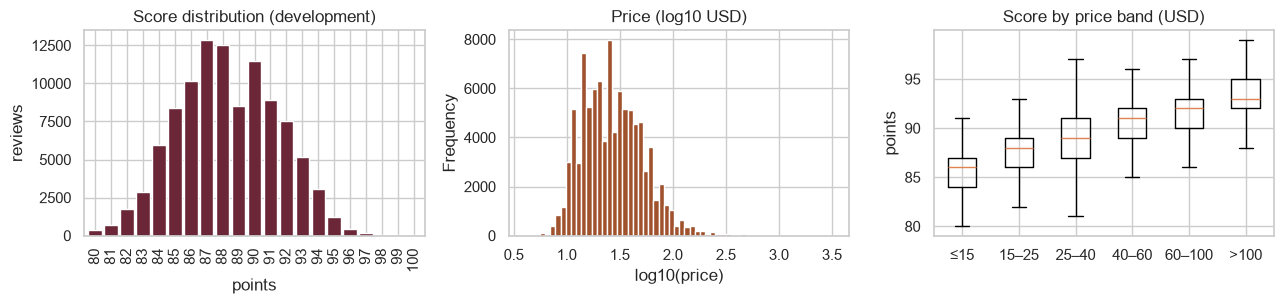

points: mean 88.32, median 88, SD 3.16, share 90+ 37.3%, share ≥95 1.92%, integer-valued: True
price: median $25, 90th pct $65, 99th $160, max $3,300


In [14]:
# 2.3a Scores and prices (development data only)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
dev["points"].value_counts().sort_index().plot.bar(ax=ax[0], color="#6b2737", width=0.85)
ax[0].set(title="Score distribution (development)", xlabel="points", ylabel="reviews")
np.log10(dev["price"].dropna()).plot.hist(ax=ax[1], bins=60, color="#a0522d")
ax[1].set(title="Price (log10 USD)", xlabel="log10(price)")
bands = pd.cut(dev["price"], [0, 15, 25, 40, 60, 100, 4000], labels=["≤15", "15–25", "25–40", "40–60", "60–100", ">100"])
ax[2].boxplot([dev.loc[bands == b, "points"] for b in bands.cat.categories], tick_labels=list(bands.cat.categories), showfliers=False)
ax[2].set(title="Score by price band (USD)", ylabel="points")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "p2_scores_prices.png", dpi=150); plt.show()
print(f"points: mean {dev.points.mean():.2f}, median {dev.points.median():.0f}, SD {dev.points.std():.2f}, "
      f"share 90+ {(dev.points >= 90).mean():.1%}, share ≥95 {(dev.points >= 95).mean():.2%}, integer-valued: {np.all(dev.points % 1 == 0)}")
print(f"price: median ${dev.price.median():.0f}, 90th pct ${dev.price.quantile(.9):.0f}, 99th ${dev.price.quantile(.99):.0f}, max ${dev.price.max():,.0f}")

In [15]:
# 2.3b Where are the value wines? (≤ $25 candidates, development data, groups with ≥ 300 candidates)
cand = dev[dev["price"] <= config.VALUE_MAX_PRICE].assign(value=lambda t: t["points"] >= config.VALUE_MIN_POINTS)
def value_table(col, min_n=300):
    t = cand.groupby(col).agg(candidates=("value", "size"), value_rate=("value", "mean"), median_price=("price", "median"))
    return t[t.candidates >= min_n].sort_values("value_rate", ascending=False)
print(f"overall value rate among ≤ $25 candidates: {cand.value.mean():.1%} ({len(cand):,} candidates)")
display(value_table("country").round(3))
vt = value_table("variety"); display(pd.concat([vt.head(6), vt.tail(4)]).round(3))

overall value rate among ≤ $25 candidates: 15.0% (49,097 candidates)


,candidates,value_rate,median_price
country,,,
Germany,930,0.303,17.0
Portugal,3274,0.210,14.0
Australia,1320,0.208,17.0
New Zealand,819,0.200,18.0
US,18227,0.179,18.0
Austria,415,0.173,19.0
France,8247,0.168,17.0
Greece,322,0.168,17.0
South Africa,845,0.114,15.0


,candidates,value_rate,median_price
variety,,,
Riesling,2284,0.278,17.0
Gamay,642,0.273,18.0
Portuguese Red,1460,0.270,14.0
Shiraz,423,0.270,17.0
Pinot Gris,813,0.262,18.0
Syrah,981,0.215,20.0
Merlot,1514,0.081,16.0
Tempranillo,943,0.070,15.0
Carmenère,430,0.067,13.0


**Value wines (selected rows; full lists below in 2.3g) mix wine effects with critic effects.** Among ≤ $25 candidates the value rate is 15.0%: Germany 30%, Portugal 21%, Australia 21%, … Italy 5%; Riesling 28% … Pinot Grigio 4%. Critics specialise by country (next cell), so these rates are descriptive only. H5, H6 and DM6 test them properly. Note also **Pinot Gris 26% vs Pinot Grigio 4%: the same grape** (2.4c). The label carries style, market and critic (Grigio is 58% Italy; Gris 60% US).

,reviews,top_countries
critic,,
(anonymous),24917,"US 64%, Italy 32%"
Roger Voss,23560,"France 73%, Portugal 22%"
Michael Schachner,14046,"Spain 43%, Chile 29%"
Kerin O’Keefe,9697,Italy 100%
Paul Gregutt,8868,"US 98%, Canada 2%"
Virginie Boone,8708,US 100%
Matt Kettmann,5730,"US 100%, Chile 0%"
Joe Czerwinski,4766,"Australia 40%, New Zealand 25%"
Sean P. Sullivan,4461,"US 99%, Canada 1%"


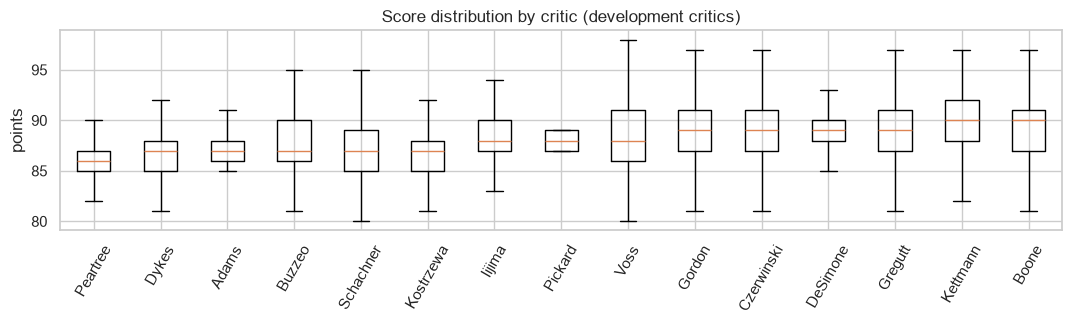

In [16]:
# 2.3c Critics: who reviews what (counts, all data) and how they score (development data)
regions = (df.assign(critic=df["taster_name"].fillna("(anonymous)"))
             .groupby("critic")["country"].agg(reviews="size", top_countries=lambda s: ", ".join(f"{c} {p:.0%}" for c, p in s.value_counts(normalize=True).head(2).items())))
display(regions.sort_values("reviews", ascending=False))
named = dev[dev["taster_name"].notna()]
order = named.groupby("taster_name")["points"].median().sort_values().index
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.boxplot([named.loc[named.taster_name == c, "points"] for c in order], tick_labels=[c.split()[-1] for c in order], showfliers=False)
ax.set(title="Score distribution by critic (development critics)", ylabel="points"); plt.xticks(rotation=60)
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "p2_scores_by_critic.png", dpi=150); plt.show()

**Critics specialise.** O'Keefe reviews only Italy, Schachner mostly Spain and Chile, and several critics only the US: the region confound of Phase 1's R2. Score distributions also differ by critic.

In [17]:
# 2.3d The tasting notes: length and vocabulary vs score (development data)
dev["n_words"] = dev["description"].str.split().str.len()
by_len = dev.groupby(pd.qcut(dev["n_words"], 5), observed=True)["points"].agg(["mean", "size"]).round(2)
by_len.index = by_len.index.astype(str); display(by_len.rename(columns={"mean": "mean points", "size": "reviews"}))
print(f"Spearman(note length, points) = {dev['n_words'].corr(dev['points'], method='spearman'):.2f}")
# Words most over-represented in 93+ vs ≤ 85 notes (log-odds ratio with a +1 prior, words in ≥ 200 notes)
from sklearn.feature_extraction.text import CountVectorizer
cv = CountVectorizer(min_df=200, stop_words="english", binary=True)
X = cv.fit_transform(dev["description"]); vocab = np.array(cv.get_feature_names_out())
hi, lo = (dev["points"] >= 93).to_numpy(), (dev["points"] <= 85).to_numpy()
p_hi = (np.asarray(X[hi].sum(0)).ravel() + 1) / (hi.sum() + 2); p_lo = (np.asarray(X[lo].sum(0)).ravel() + 1) / (lo.sum() + 2)
lor = np.log(p_hi / (1 - p_hi)) - np.log(p_lo / (1 - p_lo))
words = pd.DataFrame({"word": vocab, "log_odds_93plus_vs_85minus": lor}).sort_values("log_odds_93plus_vs_85minus")
words["evaluative (frozen list)"] = words["word"].isin(set(config.EVALUATIVE_TERMS))
display(pd.concat([words.tail(15).iloc[::-1], words.head(15)]).round(2).reset_index(drop=True))

,mean points,reviews
n_words,,
"(2.999, 31.0]",85.99,21037
"(31.0, 37.0]",87.48,21186
"(37.0, 42.0]",88.35,19237
"(42.0, 49.0]",89.28,20815
"(49.0, 135.0]",90.63,19829


Spearman(note length, points) = 0.51


,word,log_odds_93plus_vs_85minus,evaluative (frozen list)
0,2022,6.49,False
1,2025,6.39,False
2,2023,5.96,False
3,2030,5.96,False
4,2024,5.91,False
5,2021,5.51,False
6,2020,5.42,False
7,decade,5.20,False
8,superb,5.04,True
9,gorgeous,4.78,True


**The tasting notes carry the signal, and one item is a leak.**
- **Length:** longer notes go with higher scores (Spearman ρ = 0.51).
- **Drinking windows** dominate the high-score words: "2022", "2025", "2030", "decade". Then come verdict words ("superb", "gorgeous") and prestige places ("Barolo", "premier", "site").
- **The low end:** "everyday", "watery", "bland", "simple", "generic", "pizza".
- **⚠ The token "92" is a target leak, not vocabulary.** 671 barrel-sample notes *open with the score range* ("90–92. Barrel sample."). See 2.4a.

In [18]:
# 2.3e Vintage, designation and wine colour vs score (development data)
by_vintage = dev[dev["vintage"].between(2000, 2016)].groupby("vintage")["points"].agg(["mean", "size"]).round(2)
display(by_vintage.T)
des = dev.assign(has_designation=dev["designation"].notna()).groupby("has_designation")["points"].agg(["mean", "size"]).round(2)
display(des)
# Preliminary colour map from variety names (frozen properly in Phase 3 for H5)
reds = ["Pinot Noir", "Cabernet Sauvignon", "Red Blend", "Bordeaux-style Red Blend", "Syrah", "Merlot", "Zinfandel", "Malbec",
        "Sangiovese", "Nebbiolo", "Tempranillo", "Rhône-style Red Blend", "Cabernet Franc", "Grenache", "Shiraz", "Gamay", "Petite Sirah", "Barbera"]
whites = ["Chardonnay", "Sauvignon Blanc", "Riesling", "White Blend", "Pinot Gris", "Grüner Veltliner", "Pinot Grigio",
          "Gewürztraminer", "Viognier", "Chenin Blanc", "Albariño", "Bordeaux-style White Blend", "Vermentino", "Moscato"]
col = np.select([dev["variety"].isin(reds), dev["variety"].isin(whites), dev["variety"].str.contains("Rosé|Rose", na=False)], ["red", "white", "rosé"], "other / unmapped")
print("preliminary colour coverage:", pd.Series(col).value_counts(normalize=True).round(3).to_dict())

vintage,2000.0,2001.0,2002.0,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0
mean,87.39,87.38,87.74,88.43,88.73,88.33,88.18,88.11,88.16,88.29,88.11,88.04,88.62,88.84,88.88,88.33,87.36
size,750.00,682.00,351.00,568.00,1692.00,3465.00,5498.00,6578.00,6749.00,8536.00,9969.00,9392.00,10903.00,10931.00,11128.00,6852.00,2596.00


,mean,size
has_designation,,
False,87.57,29811
True,88.62,72293


preliminary colour coverage: {'red': 0.502, 'white': 0.258, 'other / unmapped': 0.21, 'rosé': 0.03}


**Vintage, designation, colour:** 2004–2014 vintages average about 88–89, while 2000–02 and 2016 average about 87.4 (vintage interacts with review timing, see 2.3g). A named designation averages 88.6 vs 87.6 without (H3 sanity check). The preliminary colour map here is superseded by the map in 2.4c (frozen in Phase 2 revision 3; known false positives from winery names are fixed in Phase 3, before H5 uses it).

In [19]:
# 2.3g Score heaping around the value threshold; price by vintage; full value tables; R3 evidence (development data)
display(dev["points"].value_counts().sort_index().loc[85:93].to_frame("reviews").T)
display(dev[dev["vintage"].between(2000, 2016)].groupby("vintage")["price"].median().to_frame("median price").T)
display(value_table("country").round(3)); display(value_table("variety").round(3))
r3 = {f: int(len(dev[dev.fold == f]) - len(drop_titles_seen_in_training(dev[dev.fold == f], dev[dev.fold != f]))) for f in sorted(dev.fold.unique()) if f >= 0}
print("R3 evidence, test rows dropped because their title appears in training, by development fold:", r3)

points,85,86,87,88,89,90,91,92,93
reviews,8370,10162,12837,12509,8505,11450,8913,7539,5159


vintage,2000.0,2001.0,2002.0,2003.0,2004.0,2005.0,2006.0,2007.0,2008.0,2009.0,2010.0,2011.0,2012.0,2013.0,2014.0,2015.0,2016.0
median price,20.0,18.0,19.0,39.0,40.0,32.0,27.0,26.0,27.0,26.0,25.0,24.0,28.0,28.0,25.0,20.0,16.0


,candidates,value_rate,median_price
country,,,
Germany,930,0.303,17.0
Portugal,3274,0.210,14.0
Australia,1320,0.208,17.0
New Zealand,819,0.200,18.0
US,18227,0.179,18.0
Austria,415,0.173,19.0
France,8247,0.168,17.0
Greece,322,0.168,17.0
South Africa,845,0.114,15.0


,candidates,value_rate,median_price
variety,,,
Riesling,2284,0.278,17.0
Gamay,642,0.273,18.0
Portuguese Red,1460,0.270,14.0
Shiraz,423,0.270,17.0
Pinot Gris,813,0.262,18.0
Syrah,981,0.215,20.0
Albariño,357,0.213,19.0
Gewürztraminer,470,0.209,18.0
Viognier,540,0.198,20.0


R3 evidence, test rows dropped because their title appears in training, by development fold: {np.int64(0): 40, np.int64(1): 30, np.int64(3): 16, np.int64(4): 51}


**More exploration:**
- **Score heaping:** critics avoid 89. In development data 88 has 12,509 reviews, **89 only 8,505**, and 90 has 11,450. So the 90+ value label sits right where critics round up. That's a reason for Phase 1's A2 sensitivity check at 88+ / 92+.
- **Price by vintage:** medians rise with age (older vintages reviewed in 2017 are pricier, later-release wines), which supports the review-timing explanation of the vintage pattern.
- **Full ≥ 300-candidate value tables** are shown above.
- **R3 evidence:** test rows dropped because their title appears in training are 40 / 30 / 16 / 51 in development folds 0 / 1 / 3 / 4.

In [20]:
# 2.3f Near-duplicate notes (structure only, all reviews): how many exist? This decides whether DM5 is measurable
from datasketch import MinHash, MinHashLSH
def shingles(t, n=5):
    w = t.lower().split(); return {" ".join(w[i:i + n]) for i in range(max(1, len(w) - n + 1))}
texts = df["description"].drop_duplicates()
lsh, sigs = MinHashLSH(threshold=0.3, num_perm=config.DM5_NUM_PERM), {}   # loose LSH for candidates, then EXACT Jaccard
for i, t in texts.items():
    m = MinHash(num_perm=config.DM5_NUM_PERM, seed=config.SEED); m.update_batch([s.encode() for s in shingles(t)]); sigs[i] = m; lsh.insert(i, m)
cand = {tuple(sorted((i, j))) for i in sigs for j in lsh.query(sigs[i]) if i != j}
sh = {i: shingles(texts[i]) for pair in cand for i in pair}
jac = pd.Series({p: len(sh[p[0]] & sh[p[1]]) / len(sh[p[0]] | sh[p[1]]) for p in cand})
print(f"distinct notes: {len(texts):,}; LSH candidate pairs: {len(cand):,}")
display(pd.Series({f"pairs with Jaccard ≥ {t}": int((jac >= t).sum()) for t in (0.4, 0.5, 0.7, 0.8)}).to_frame("count"))
top = jac.sort_values(ascending=False).head(3)
for (i, j), v in top.items():
    print(f"J={v:.2f} | {df.loc[i, 'title'][:60]} || {df.loc[j, 'title'][:60]}")
hi = jac[jac >= config.DM5_TAU]
kind = pd.Series({p: ("same winery" if df.loc[p[0], "winery"] == df.loc[p[1], "winery"] else "different wineries") for p in hi.index})
same_fold = all(df.loc[p[0], "fold"] == df.loc[p[1], "fold"] for p in hi.index)
print(f"{len(hi)} pairs at J ≥ {config.DM5_TAU}: {kind.value_counts().to_dict()}; all within one fold: {same_fold}")

distinct notes: 119,955; LSH candidate pairs: 1,196


,count
pairs with Jaccard ≥ 0.4,50
pairs with Jaccard ≥ 0.5,43
pairs with Jaccard ≥ 0.7,20
pairs with Jaccard ≥ 0.8,8


J=1.00 | Hargrave 1998 Merlot (North Fork of Long Island) || Castello di Borghese 1998 Hargrave Vineyard Merlot (North Fo
J=0.95 | Torbreck 2006 The Struie Shiraz (Barossa) || Torbreck 2006 The Struie Shiraz (Barossa)
J=0.92 | Herdade da Capela 2013 Terras de Pias Reserva Red (Alentejan || Herdade da Capela 2013 Terras de Pias Reserva Red (Alentejo)
43 pairs at J ≥ 0.5: {'different wineries': 24, 'same winery': 19}; all within one fold: True


**Near-duplicate notes are rare, and most aren't relistings.** Across 119,955 distinct notes, exact Jaccard (after loose LSH candidate generation) gives 50 / **43** / 20 / 8 pairs at ≥ 0.4 / **0.5** / 0.7 / 0.8 (5-word shingles).
- **About a third are the same wine relisted** ("Alentejano" vs "Alentejo"; a vineyard name moved into the winery field).
- **Most are the same critic's note recycled or attached to a different wine:** near-verbatim notes on wines from different producers, or on a producer's red and white (per critic round 3).
- **Every pair is within one fold,** so nothing leaks across folds or the lockbox (printed above).
- So catalogue hygiene (BO4) matters more as **mis-attached notes** than as duplicate listings. Phase 3 flags these ~80 rows as possible label noise.

**DM5 as written in Phase 1 can't be measured:** "recall ≥ 0.9 on a 10k sample" would contain fewer than one true pair. **Loop back to Phase 1** (CRISP-DM's Business ↔ Data Understanding loop): DM5 is re-specified in §1.3 (original kept, struck through and dated). It now uses the **full corpus**: recall on ~1,670 synthetic positives (2–8% word edits, exact J ≥ 0.5; sized by a Phase 2 simulation), a false-flag rate on random pairs, and precision on the 43 real pairs with a labelling rule fixed in advance.

### 2.4 Verify data quality

**CRISP-DM output:** Data quality report

In [21]:
# 2.4 Verify data quality: every issue found, with the rows affected
title_years = df["title"].str.count(r"\b(?:19|20)\d{2}\b")
rt = df[df["title"].duplicated(keep=False)]
g = rt.groupby("title")
issues = pd.DataFrame([
    ("Exact duplicate rows", raw.duplicated().sum()),
    ("Repeat reviews of an already-reviewed title", int((df["title"].value_counts() - 1).clip(lower=0).sum())),
    ("…titles reviewed only by one named critic", int(rt[rt.taster_name.notna()].groupby("title")["taster_name"].agg(lambda s: s.nunique() == 1 and len(s) > 1).sum())),
    ("Duplicated note text (development data; see 2.4c)", int(dev["description"].duplicated(keep=False).groupby(dev["description"]).any().sum())),
    ("Missing price", int(df["price"].isna().sum())),
    ("Missing critic name (anonymous)", int(df["taster_name"].isna().sum())),
    ("Missing country / province", int(df["country"].isna().sum())),
    ("Missing variety", int(df["variety"].isna().sum())),
    ("Missing designation", int(df["designation"].isna().sum())),
    ("Missing region_1 / region_2", f"{df['region_1'].isna().sum():,} / {df['region_2'].isna().sum():,} (region_2 only exists for US)"),
    ("No vintage year in title (non-vintage wines)", int(df["vintage"].isna().sum())),
    ("Title has more than one year (vintage parse ambiguous)", int((title_years > 1).sum())),
    ("Parsed vintage before 1990 (often a winery name, e.g. '1912 Winemakers')", int((df["vintage"] < 1990).sum())),
    ("Price above $1,000", int((df["price"] > 1000).sum())),
    ("Critic name containing a non-breaking space", int(df["taster_name"].dropna().str.contains("\xa0").sum())),
    ("Notes shorter than 10 words", int((df["description"].str.split().str.len() < 10).sum())),
], columns=["check", "rows affected"]).set_index("check")
display(issues)

,rows affected
check,
Exact duplicate rows,9983
Repeat reviews of an already-reviewed title,1148
…titles reviewed only by one named critic,729
Duplicated note text (development data; see 2.4c),13
Missing price,8395
Missing critic name (anonymous),24917
Missing country / province,59
Missing variety,1
Missing designation,34545


*Basic checks; the deeper audits follow.*

In [22]:
# 2.4a Leakage audit of the note text
from winevalue.text_audit import flag_score_leaks, is_barrel_sample, SCORE_RANGE_AT_START
flags = flag_score_leaks(df["description"]).assign(barrel_sample=is_barrel_sample(df["title"], df["description"]), fold=df["fold"])
display(flags.groupby("fold")[["score_range_at_start", "explicit_points", "verdict_label", "currency_amount", "barrel_sample"]].sum()
             .rename(index={LOCKBOX: f"{LOCKBOX} (lockbox: counts only)"}))
# How much does a leading score range reveal? (development data only)
rng = dev["description"].str.extract(r"^\s*\(?(8\d|9\d|100)\s*[-–—]\s*(8\d|9\d|100)").astype(float).dropna()
mid = rng.mean(axis=1); pts = dev.loc[rng.index, "points"]
print(f"development notes opening with a score range: {len(rng)}; recorded score == range midpoint: {(pts == mid).mean():.1%}; "
      f"inside the range: {pts.between(rng[0], rng[1]).mean():.1%}; MAE of the midpoint: {(pts - mid).abs().mean():.3f} points")
print(f"barrel-sample reviews with a price: {df.loc[flags.barrel_sample, 'price'].notna().mean():.1%} (so they're almost never ≤ $25 candidates)")
starts = df.loc[flags.score_range_at_start, "description"]
print(f"range forms: em dash {int(starts.str.match(r'^\s*\(?\d+\s*—').sum())}, '98-100'-type {int(starts.str.match(r'^\s*\(?\d{2}\s*[-–—]\s*100').sum())}; "
      f"duplicated-note groups overall: {int(df['description'].duplicated(keep=False).groupby(df['description']).any().sum())}")

,score_range_at_start,explicit_points,verdict_label,currency_amount,barrel_sample
fold,,,,,
-1,0,7,62,52,0
0,671,0,4,0,671
1,0,11,54,167,0
2 (lockbox: counts only),0,0,0,0,0
3,0,2,63,79,0
4,0,0,1,35,0


development notes opening with a score range: 671; recorded score == range midpoint: 99.7%; inside the range: 99.9%; MAE of the midpoint: 0.008 points
barrel-sample reviews with a price: 1.5% (so they're almost never ≤ $25 candidates)
range forms: em dash 41, '98-100'-type 3; duplicated-note groups overall: 33


**2.4a The target is written into some notes.**
- **What:** 671 development notes (all fold 0, Roger Voss **barrel samples**; 41 use an em dash, three use "98-100") open with the score range, e.g. "90–92. Barrel sample.". The **recorded score equals the range midpoint 99.7% of the time** (MAE 0.008 points).
- **Other text leaks:** 20 notes state a score ("rated 92 points", "a 90-point wine", "90+ rating"), 184 carry WineEnthusiast labels ("Best Buy", "Editors' Choice", "Cellar Selection"), and 333 contain a price ("an under-$15 red", "10 bucks"), which matters for the price-free model (R-2). Regexes are restricted to plausible scores (80–100), so "14-15% alcohol" can't match (tested).
- **Who it affects:** barrel samples are pre-release assessments and almost never priced (1.5%), so they barely touch the ≤ $25 shortlist (BSC1/BSC2). But they teach any model trained on fold 0 that "9x" tokens are scores.
- **Decision (Phase 3, all models):** drop barrel-sample reviews (671) from training and evaluation; strip explicit score mentions and verdict labels; replace prices with a `_price_` token. This is a leakage fix, separate from the frozen evaluative list.

In [23]:
# Does the leak change the Phase 1 feasibility numbers? Fold 0 (where all barrel samples are), re-run without them
from winevalue.models import GroupMeanBaseline, quick_text_model, QUALITY_INPUTS
from winevalue.metrics import mae, within
from winevalue.splits import drop_titles_seen_in_training
barrel = is_barrel_sample(dev["title"], dev["description"])
out = []
for f in sorted(x for x in dev["fold"].unique() if x >= 0):
    for label, data in [("as in Phase 1", dev), ("barrel samples removed", dev[~barrel])]:
        tr = data[data["fold"] != f]; te = drop_titles_seen_in_training(data[data["fold"] == f], tr)
        p = quick_text_model().fit(tr[QUALITY_INPUTS], tr["points"]).predict(te[QUALITY_INPUTS])
        b = GroupMeanBaseline().fit(tr, tr["points"]).predict(te)
        out.append({"fold": f, "version": label, "MAE reduction vs v×c": 1 - mae(te.points, p) / mae(te.points, b)})
display(pd.DataFrame(out).pivot(index="fold", columns="version", values="MAE reduction vs v×c").round(3))

version,as in Phase 1,barrel samples removed
fold,,
0,0.327,0.349
1,0.332,0.330
3,0.119,0.117
4,0.316,0.316


**Effect on Phase 1's feasibility numbers:** removing barrel samples *raises* fold 0's MAE reduction from 32.7% to 34.9%, and folds 1/3/4 change by ≤ 0.2 pp (33.2 → 33.0, 11.9 → 11.7, 31.6 → 31.6%). The leak didn't inflate Phase 1, and the pre-registered targets stand.

In [24]:
# What does the frozen evaluative mask leave behind? (DM1b limitation; the frozen list itself is unchanged)
from winevalue.models import mask_evaluative
hi93 = dev[dev["points"] >= 93]
masked = mask_evaluative(hi93["description"])
resid = pd.Series({
    "93+ development notes with a 20xx year (before masking)": int(hi93["description"].str.contains(r"\b20\d{2}\b").sum()),
    "…still containing a 20xx year after masking (e.g. 'now–2025')": int(masked.str.contains(r"\b20\d{2}\b").sum()),
    "…containing 'decade' (not in the frozen list)": int(masked.str.contains(r"\bdecades?\b", case=False).sum()),
    "…containing 'N years' phrases": int(masked.str.contains(r"\b\d+\s+years?\b|\b(?:five|ten|several|many)\s+years\b", case=False).sum()),
})
display(resid.to_frame("notes"))

,notes
93+ development notes with a 20xx year (before masking),3923
…still containing a 20xx year after masking (e.g. 'now–2025'),920
…containing 'decade' (not in the frozen list),250
…containing 'N years' phrases,1038


**What the frozen mask leaves behind (a DM1b limitation; the frozen list isn't changed):** of 3,923 development 93+ notes with a 20xx year, 920 still contain one after masking (e.g. "now–2025"). 250 contain "decade" and 1,038 contain "N years" phrases. So DM1b's 87% retention is an upper bound on "signal beyond verdict words". Phase 4 reports a stricter mask alongside it as a sensitivity check.

In [25]:
# Vintage rule: Phase 1 parser vs the revised rule (strip winery prefix, first year)
v_new = extract_vintage(df["title"], df["winery"])
changed = df.loc[(df["vintage"] != v_new) & ~(df["vintage"].isna() & v_new.isna()), ["title", "winery"]].assign(old=df["vintage"], new=v_new)
print(f"titles whose vintage changes: {len(changed)}; parsed vintages before 1990: {int((df['vintage'] < 1990).sum())} → {int((v_new < 1990).sum())}")
display(changed.head(8))

titles whose vintage changes: 17; parsed vintages before 1990: 69 → 52


,title,winery,old,new
review_id,,,,
7986,Guidi 1929 2012 Aurea Riserva (Vernaccia di San Gimignano),Guidi 1929,1929.0,2012.0
9728,1912 Winemakers 2011 Vinhas Velhas Branco White (Douro),1912 Winemakers,1912.0,2011.0
38689,1912 Winemakers 2009 Piorro Reserva Red (Douro),1912 Winemakers,1912.0,2009.0
41070,1912 Winemakers 2013 Piorro Branco Colheita White (Douro),1912 Winemakers,1912.0,2013.0
54720,1912 Winemakers 2009 Encosta do Bocho Grand Reserva Red (Douro),1912 Winemakers,1912.0,2009.0
54748,Alvear NV Solera 1927 Pedro Ximénez (Montilla-Moriles),Alvear,1927.0,NaN
56426,Arthur Metz NV 1904 Cuvée Spéciale Brut Sparkling (Crémant d'Alsace),Arthur Metz,1904.0,NaN
61105,1912 Winemakers 2011 Piorro Colheita Red (Douro),1912 Winemakers,1912.0,2011.0


**Vintage rule, corrected.** The Phase 1 parser took the first year in the title, which picks years inside winery names. The revised rule strips the winery name (titles always start with it), treats a title with **"NV" before the first year as non-vintage** ("Alvear NV Solera 1927", "Arthur Metz NV 1904"), and then takes the **first** remaining year. It changes 17 titles, and pre-1990 vintages fall from 69 to **52, all genuine** (Rivesaltes 1945, Port, Mosel). Later years in a title are planting or cuvée years ("Vignes de 1939"), so "nearest the end" (round-1 draft) would have been wrong. Implemented in `extract_vintage(title, winery)` and unit-tested; applied from Phase 3.

In [26]:
# 2.4c Identity checks: is `title` a wine key? duplicate notes; synonyms; encodings; pseudo-provinces; prices
rt = df[df["title"].duplicated(keep=False)]
g = rt.groupby("title")
named_same = int(rt[rt.taster_name.notna()].groupby("title")["taster_name"].agg(lambda s: s.nunique() == 1 and len(s) > 1).sum())
print(f"repeat titles: {rt.title.nunique()}; with different varieties (so different wines): {int((g['variety'].nunique() > 1).sum())}; "
      f"with different prices: {int((g['price'].nunique() > 1).sum())}; reviewed only by one named critic: {named_same}")
dup_notes = dev[dev["description"].duplicated(keep=False)]
dn = dup_notes.groupby("description")
print(f"development: duplicated note texts {dn.ngroups}; attached to different titles {int((dn['title'].nunique() > 1).sum())}, "
      f"different wineries {int((dn['winery'].nunique() > 1).sum())}, different varieties {int((dn['variety'].nunique() > 1).sum())}")
syn = df.assign(grape=grape_canonical(df["variety"]))
merged = syn[syn["grape"] != syn["variety"]].groupby(["grape", "variety"]).size().sort_values(ascending=False)
print(f"labels merged by the synonym map: {merged.index.get_level_values(1).nunique()} labels, {int(merged.sum()):,} reviews")
display(syn[syn["grape"].isin(["Pinot Gris", "Syrah"])].groupby(["grape", "variety"])["country"]
          .agg(reviews="size", top_country=lambda s: f"{s.value_counts().index[0]} {s.value_counts(normalize=True).iloc[0]:.0%}"))
colour = wine_colour(df["variety"], df["title"])
print("frozen colour map coverage:", colour.value_counts(normalize=True).round(3).to_dict())
print("largest unmapped labels:", df.loc[colour == "unmapped", "variety"].value_counts().head(8).to_dict())
text_cols = ["title", "winery", "designation", "description", "taster_name", "province", "region_1"]
enc = pd.DataFrame({c: {"non-breaking space": int(df[c].dropna().str.contains("\xa0").sum()),
                        "mojibake (Ã or Â)": int(df[c].dropna().str.contains("Ã|Â").sum())} for c in text_cols}).T
display(enc[enc.sum(axis=1) > 0])
wk = df["winery"].str.casefold().str.replace(r"\s+", " ", regex=True).str.strip()
print(f"winery names that differ only by case/whitespace: {int((df.groupby(wk)['winery'].nunique() > 1).sum())} groups")
pseudo = df["province"].str.contains(r"(?:^| )Other$", regex=True, na=False) | (df["province"] == df["country"])
print("pseudo-provinces:", df.loc[pseudo, "province"].value_counts().head(8).to_dict(), f"(total {int(pseudo.sum())})")
hi = df[df["price"] > 1000][["title", "price", "variety"]].sort_values("price", ascending=False)
year_price = df[df["price"].between(1900, 2017) & (df["price"] == df["vintage"])]
display(hi)
print(f"rows where price equals the vintage year: {len(year_price)}")

repeat titles: 934; with different varieties (so different wines): 250; with different prices: 474; reviewed only by one named critic: 729
development: duplicated note texts 13; attached to different titles 13, different wineries 6, different varieties 5
labels merged by the synonym map: 43 labels, 5,891 reviews


reviews    top_country
grape      variety                              
Pinot Gris Grauburgunder       14    Germany 50%
           Pinot Grigio       980      Italy 58%
           Pinot Gris        1324         US 60%
Syrah      Shiraz             790  Australia 74%
           Syrah             3828         US 79%

frozen colour map coverage: {'red': 0.59, 'white': 0.303, 'sparkling': 0.043, 'rosé': 0.035, 'unmapped': 0.021, 'fortified': 0.007}
largest unmapped labels: {'Gros and Petit Manseng': 46, 'Malvasia': 43, 'Müller-Thurgau': 41, 'Graciano': 40, 'Traminer': 37, 'Frappato': 35, 'Fernão Pires': 34, 'Muscat Canelli': 34}


,non-breaking space,mojibake (Ã or Â)
title,22,2
winery,15,0
designation,7,2
description,2,1
taster_name,3290,0


winery names that differ only by case/whitespace: 29 groups
pseudo-provinces: {'France Other': 623, 'Other': 506, 'Australia Other': 231, 'Italy Other': 126, 'England': 63, 'Spain Other': 58, 'Moldova': 51, 'Chile': 48} (total 1921)


,title,price,variety
review_id,,,
80290,Château les Ormes Sorbet 2013 Médoc,3300.0,Bordeaux-style Red Blend
15840,Château Pétrus 2014 Pomerol,2500.0,Bordeaux-style Red Blend
98380,Domaine du Comte Liger-Belair 2010 La Romanée,2500.0,Pinot Noir
120391,Blair 2013 Roger Rose Vineyard Chardonnay (Arroyo Seco),2013.0,Chardonnay
65352,Château Pétrus 2011 Pomerol,2000.0,Bordeaux-style Red Blend
113564,Domaine du Comte Liger-Belair 2005 La Romanée,2000.0,Pinot Noir
1558,Château Margaux 2009 Margaux,1900.0,Bordeaux-style Red Blend
111753,Château Lafite Rothschild 2010 Pauillac,1500.0,Bordeaux-style Red Blend
111755,Château Cheval Blanc 2010 Saint-Émilion,1500.0,Bordeaux-style Red Blend


rows where price equals the vintage year: 1


**2.4c Identity and encoding checks:**
- **`title` isn't a wine key.** 250 of 934 repeat titles cover *different wines* (e.g. a red and a white sold under one title), and 474 have different prices. Repeat-title analyses therefore use title + variety.
- **Duplicated notes** (13 groups in development data, 33 overall) are attached to *different* titles. Some are the same wine relisted (Hargrave ≡ "Castello di Borghese Hargrave Vineyard"), some are notes pasted onto another wine, and 2 are barrel samples. Decision: keep **one** row per duplicated note (the first), drop the rest.
- **Grape synonyms.** `grape_canonical` (in `winevalue.grapes`) merges 43 labels / 5,891 reviews (Shiraz → Syrah, Pinot Grigio → Pinot Gris, Garnacha → Grenache, …), using standard ampelographic synonyms only, never scores. Raw `variety` stays unchanged for the frozen simple rules and the variety × country baseline (pre-registration kept). The canonical grape is used for DM4, H5 and the app.
- **Colour map (frozen now, for H5).** `wine_colour(variety, title)`: title style words (rosé, Brut / sparkling, Port / Sherry) override the grape; blends take the first-listed grape's colour. It covers **97.9%** of reviews (59.0% red, 30.3% white, 4.3% sparkling, 3.5% rosé, 0.7% fortified), built from grape knowledge and title text only, before any colour × value table. Unmapped labels are listed above (largest: "Gros and Petit Manseng", 46).
- **Encoding.** Non-breaking spaces appear in 3,290 critic names (only Anne Krebiehl MW, consistent across folds), 22 titles, 15 winery rows and 7 designations; mojibake ("Ã"/"Â") in 5 cells across 3 fields; 29 winery names differ only by case or whitespace. Decision: normalise whitespace and case-fold winery keys for models. The frozen winery track-record rule keeps the raw name (pre-registration), with an effect of ≤ 29 groups.
- **Pseudo-provinces** ("France Other", "Other", "Australia Other", province = country; 1,921 rows) become "Unknown province" for models; the frozen province rule is unchanged.
- **Prices > $1,000**, checked by hand:
  - the first-growth Bordeaux and Burgundy prices are plausible;
  - **"Château les Ormes Sorbet 2013 Médoc" at $3,300** and **Blair 2013 Chardonnay at $2,013** (price = vintage year) are errors;
  - Knoll Smaragd Grüner Veltliner at $1,100 is implausible.
  - Decision: set those 3 to missing (the real maximum is then $2,500, Pétrus).

In [27]:
# 2.4b Human noise floor, done properly (development data only)
from itertools import combinations
def pairs(frame, same_critic):
    keys = ["title", "variety", "taster_name"] if same_critic else ["title", "variety"]
    rows = []
    for _, g in frame[frame["taster_name"].notna()].groupby(keys):
        if len(g) < 2: continue
        for (i, a), (j, b) in combinations(g[["points", "taster_name", "price"]].iterrows(), 2):
            if same_critic or a.taster_name != b.taster_name:
                rows.append((abs(a.points - b.points), min(a.price, b.price) if pd.notna(a.price) and pd.notna(b.price) else np.nan))
    return pd.DataFrame(rows, columns=["diff", "price"])
from scipy.stats import norm
res = []
for label, same in [("same critic, same title + variety", True), ("different critics, same title + variety", False)]:
    p = pairs(dev, same)
    for band, q in [("all prices", p), ("≤ $25", p[p.price <= config.VALUE_MAX_PRICE])]:
        if len(q) < 20: continue
        # one review = expected score + noise e, e ~ N(0, σ²); a pair difference has variance 2σ², so σ = RMS(diff) / √2.
        # A perfect predictor of the expected score (continuous) is within ±2 of a single review with P = 2Φ(2/σ) − 1.
        sigma = np.sqrt((q["diff"] ** 2).mean() / 2)
        res.append({"comparison": label, "price band": band, "pairs": len(q), "mean |diff|": q["diff"].mean(),
                    "exact match": (q["diff"] == 0).mean(), "within ±2": (q["diff"] <= 2).mean(),
                    "implied single-read σ": sigma,
                    "ceiling: P(|error| ≤ 2) for a perfect predictor": 2 * norm.cdf(2 / sigma) - 1})
display(pd.DataFrame(res).set_index(["comparison", "price band"]).round(3))

pairs  mean |diff|  \
comparison                              price band                       
same critic, same title + variety       all prices    728        1.527   
                                        ≤ $25         304        1.618   
different critics, same title + variety all prices     39        2.256   
                                        ≤ $25          20        1.700   

                                                    exact match  within ±2  \
comparison                              price band                           
same critic, same title + variety       all prices        0.225      0.793   
                                        ≤ $25             0.181      0.770   
different critics, same title + variety all prices        0.205      0.641   
                                        ≤ $25             0.150      0.800   

                                                    implied single-read σ  \
comparison                              price band                          
same critic, same title + variety       all prices                  1.446   
                                        ≤ $25                       1.491   
different critics, same title + variety all prices                  2.166   
                                        ≤ $25                       1.565   

                                                    ceiling: P(|error| ≤ 2) for a perfect predictor  
comparison                              price band                                                   
same critic, same title + variety       all prices                                            0.833  
                                        ≤ $25                                                 0.820  
different critics, same title + variety all prices                                            0.644  
                                        ≤ $25                                                 0.799

**2.4b The human noise floor, done properly.** Pairs are now pairwise (not ranges), on the same **title + variety** (a stricter wine key), development data only. Assume one review = the wine's expected score + noise.

| Comparison | Price band | Pairs | Mean \|diff\| | Within ±2 | Implied single-review σ | Ceiling: P(within ±2) for a perfect predictor |
|---|---|---|---|---|---|---|
| Same critic | all | 728 | 1.53 | 79% | 1.45 | 0.83 |
| Same critic | ≤ $25 | 304 | 1.62 | 77% | 1.49 | **0.82** |
| Different critics | all | 39 | 2.26 | 64% | 2.17 | 0.64 |
| Different critics | ≤ $25 | 20 | 1.70 | 80% | 1.57 | 0.80 (n tiny) |

- **The √2 correction.** A difference between two reviews contains two noises, so σ = RMS(diff)/√2 and the ceiling is 2Φ(2/σ) − 1: about **0.82** for one critic at ≤ $25.
- **Correct comparison.** The Phase 1 model is scored on *unseen* critics, so the relevant ceiling lies between the **cross-critic** values (0.64 at all prices, n = 39; 0.80 at ≤ $25, n = 20) and the same-critic value (0.82). The ceiling is roughly **0.64–0.83**, and every figure rests on small, selected samples. The model's 0.69 is therefore **not** "close to critics' own consistency". There is likely, but uncertain, headroom.
- **Caveat:** re-reviewed wines are a selected sample.

In [28]:
# Co-author pair across the lockbox boundary: Jeff Jenssen (lockbox) and Mike DeSimone (fold 4) share @worldwineguys.
# Text-only check with the Phase 1 style classifier: how often is one mistaken for the other on held-out notes?
pred = clf.classes_[held.argmax(1)]
truth = te_txt["taster_name"].to_numpy()
for a, b in [("Jeff Jenssen", "Mike DeSimone"), ("Mike DeSimone", "Jeff Jenssen")]:
    m = truth == a
    print(f"held-out {a} notes: {m.sum()}; predicted as {b}: {(pred[m] == b).mean():.1%}; correctly attributed: {(pred[m] == a).mean():.1%}")

held-out Jeff Jenssen notes: 87; predicted as Mike DeSimone: 5.7%; correctly attributed: 82.8%
held-out Mike DeSimone notes: 92; predicted as Jeff Jenssen: 6.5%; correctly attributed: 87.0%


**Co-author pair across the lockbox boundary.** Jeff Jenssen (lockbox) and Mike DeSimone (fold 4) share the handle @worldwineguys. On held-out notes, the text-only style classifier confuses them only 6–7% of the time (83% and 87% correctly attributed), and they share no titles. So the "unseen writer" premise for Jenssen is weakened only slightly. Noted as a limitation.

**Data quality report: decisions (applied in Phase 3; none changes the frozen Phase 1 design or targets):**

| Issue | Rows | Decision |
|---|---|---|
| Exact duplicate rows | 9,983 | Drop |
| **Score written in note (barrel samples)** | 671 | **Drop barrel samples** from training and evaluation |
| Explicit score / verdict label / price in note | 20 / 184 / 333 | Strip scores and labels; replace prices with `_price_` (R-2) |
| Duplicated note on different titles | 13 groups (dev), 33 overall | Keep one row per note, drop the rest |
| Repeat titles | 1,148 reviews / 934 titles (250 cover different wines) | Wine key = title + variety; keep genuine re-reviews in training; drop test rows whose title appears in training (R-3, evidence in 2.3g) |
| Missing price | 8,395 (+3 set missing) | Keep for score models; excluded from the ≤ $25 pool and the value verdict |
| Implausible prices | 3 | Set to missing |
| Anonymous critic | 24,917 | Training only; 859 style-attributed to lockbox critics dropped (R8) |
| Missing country/province/variety | 60 | "Unknown" |
| Pseudo-provinces | 1,921 | "Unknown province" for models; frozen rule unchanged |
| Missing designation / region | 28% / 16% | Missing indicator |
| Vintage parse | 17 changed | Strip the winery prefix; NV before the first year → non-vintage; else first year (tested) |
| Non-vintage | 4,285 | Non-vintage flag |
| Grape synonyms | 43 labels / 5,891 reviews | `grape_canonical` for DM4/H5/app; raw label for the frozen rules |
| Encoding / winery case variants | see 2.4c | Normalise; case-fold winery keys for models |
| Notes < 10 words | 39 | Keep; flag |
| Mask residuals (years, "decade") | see 2.4a | DM1b limitation; a stricter mask as a Phase 4 sensitivity check |
| Co-author pair Jenssen/DeSimone | – | Limitation |
| No review date | all | Limitation (vintage ↔ timing) |

> **Critic review: Phase 2.** The revisions are logged in `critiques/phase2_data_understanding_round*.md`.

---
# Phase 3 · Data Preparation

### 3.1 Select data

**CRISP-DM outputs:** Rationale for inclusion / exclusion

In [29]:
# TODO: Rows and columns per goal; leakage exclusions (price, critic) per R-2.

### 3.2 Clean data

**CRISP-DM outputs:** Data cleaning report

In [30]:
# TODO: Deduplication (fold-safe), missing values, outlier handling, text normalisation.

### 3.3 Construct data

**CRISP-DM outputs:** Derived attributes · Generated records

In [31]:
# TODO: Vintage, wine age at review, region grouping, note length, descriptor sets.

### 3.4 Integrate data

**CRISP-DM outputs:** Merged data

In [32]:
# TODO: Single table: no external sources; document why.

### 3.5 Format data

**CRISP-DM outputs:** Reformatted data · Dataset · Dataset description

In [33]:
# TODO: sklearn pipelines; save processed data.

> **Critic review: Phase 3.** The revisions are logged in `critiques/phase3_data_preparation_round*.md`.

---
# Phase 4 · Modeling

### 4.1 Select modeling technique

**CRISP-DM outputs:** Modeling technique · Modeling assumptions

In [34]:
# TODO: DM1–DM6 techniques and their assumptions.

### 4.2 Generate test design

**CRISP-DM outputs:** Test design

In [35]:
# TODO: Critic-fold CV on development folds (lockbox untouched); metrics per DM goal.

### 4.3 Build model

**CRISP-DM outputs:** Parameter settings · Models · Model descriptions

In [36]:
# TODO: Fit and tune; save artifacts.

### 4.4 Assess model

**CRISP-DM outputs:** Model assessment · Revised parameter settings

In [37]:
# TODO: CV results vs baselines; error analysis by critic, country, grape.

> **Critic review: Phase 4.** The revisions are logged in `critiques/phase4_modeling_round*.md`.

---
# Phase 5 · Evaluation

### 5.1 Evaluate results

**CRISP-DM outputs:** Assessment w.r.t. business success criteria · Approved models

In [38]:
# TODO: Single lockbox run; BSC1–BSC5.

### 5.2 Review process

**CRISP-DM outputs:** Review of process

In [39]:
# TODO: Audit all phases for leakage and missed steps.

### 5.3 Determine next steps

**CRISP-DM outputs:** List of possible actions · Decision

In [40]:
# TODO: Go/no-go with reasons.

> **Critic review: Phase 5.** The revisions are logged in `critiques/phase5_evaluation_round*.md`.

---
# Phase 6 · Deployment

### 6.1 Plan deployment

**CRISP-DM outputs:** Deployment plan

In [41]:
# TODO: Value Finder app (deployment/app.py), saved pipeline.

### 6.2 Plan monitoring & maintenance

**CRISP-DM outputs:** Monitoring & maintenance plan

In [42]:
# TODO: Drift, re-scoring, retraining triggers.

### 6.3 Produce final report

**CRISP-DM outputs:** Final report · Final presentation

In [43]:
# TODO: Report, Medium article, video script.

### 6.4 Review project

**CRISP-DM outputs:** Experience documentation

In [44]:
# TODO: Lessons learned.

> **Critic review: Phase 6.** The revisions are logged in `critiques/phase6_deployment_round*.md`.